# Opdracht 1: Voorspel herseninfarct

**Team:** Kwik Kwek en Kwak

| Teamlid | Kaggle-gebruikersnaam |
|---|---|
| Ghadeer Alhassany | Ghadeertjuee |
| Tonna Tekle | TTekle |
| Malak Alshehabi | MalakAlshehabi |


Competitie: *Predicting stroke 2026-27* (Kaggle, 2026).

**Inhoud**

1. Exploratieve Data Analyse
2. Evaluatie van een classificatiemodel
3. K-Nearest Neighbors
4. Decision Tree
5. Logistic Regression
6. Support Vector Machine
7. Ensembles: Random Forest, Gradient Boosting en XGBoost
8. Zelf samengesteld ensemble
9. Conclusie en advies
10. Bronnen

# 1. Exploratieve Data Analyse

In dit hoofdstuk wordt de dataset van de Kaggle-competitie *Predicting stroke 2026-27* onderzocht (Kaggle, 2026). Het doel is te voorspellen of een patiënt een herseninfarct (stroke) heeft gehad. Deze paragrafen behandelen de kolommen, de datatypes, de basisstatistieken en de vraag of de data geschikt is voor Scikit-learn. De relaties met de doelvariabele, de opschoning en de standaardisatie volgen in de volgende paragrafen.

## 1.1 Dataset inladen

Kaggle geeft aan dat de dataset al gedeeltelijk is voorbewerkt, bijvoorbeeld met dummy-kolommen (Kaggle, 2026). Het bestand `train.csv` bevat de patiënten waarmee de modellen worden getraind en getest. Het bestand `test.csv` bevat de patiënten waarvoor de voorspellingen op Kaggle worden ingeleverd. In `test.csv` ontbreekt de kolom `stroke`.

In [1]:
import time

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (GradientBoostingClassifier,
                              RandomForestClassifier, VotingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, f1_score,
                             precision_recall_curve, precision_score,
                             recall_score)
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics.pairwise import euclidean_distances, manhattan_distances
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     cross_val_predict, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBClassifier

pd.set_option("display.max_colwidth", None)

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("Vorm train.csv:", train.shape)
print("Vorm test.csv:", test.shape)
train.head()

Vorm train.csv: (33550, 22)
Vorm test.csv: (8388, 21)


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,True,False,True,...,False,True,False,False,True,False,False,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,False,False,...,False,False,True,False,True,False,False,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,True,False,True,...,False,True,False,False,True,False,False,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,True,False,False,...,False,False,True,False,False,True,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,True,False,False,...,False,False,True,False,True,False,True,False,False,0


In [2]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


## 1.2 Uitleg van de kolommen

De dataset heeft 22 kolommen. Kaggle geeft geen kolomomschrijving en laat het inschatten van de betekenis over aan de studenten (Kaggle, 2026). De uitleg hieronder is daarom afgeleid uit de kolomnamen. Er zijn vijf soorten kolommen:

- **Identificatie:** `id`, een nummer per patiënt. Dit is geen kenmerk van de patiënt zelf.
- **Numerieke kenmerken:** `age`, `avg_glucose_level` en `bmi`.
- **Binaire kenmerken:** `hypertension` en `heart_disease`, met 0 voor nee en 1 voor ja.
- **Dummy-kolommen:** een kenmerk met tekstwaarden (zoals `work_type`) is omgezet naar één kolom per waarde, met 1 als de patiënt die waarde heeft en anders 0. Dit heet *one-hot encoding*. Het gaat om `gender_*`, `ever_married_*`, `work_type_*`, `Residence_type_*` en `smoking_status_*`.
- **Doelvariabele:** `stroke`, met 1 als de patiënt een herseninfarct heeft gehad en anders 0.

De functie hieronder maakt de tabel en controleert ook dat elke kolom een uitleg heeft.

In [4]:
COLUMN_DESCRIPTIONS = {
    "id": "Identificatienummer van de patiënt, geen kenmerk.",
    "age": "Leeftijd van de patiënt in jaren (ook decimale waarden).",
    "hypertension": "Hypertensie (hoge bloeddruk): 0 = nee, 1 = ja.",
    "heart_disease": "Hartziekte: 0 = nee, 1 = ja.",
    "avg_glucose_level":
        "Gemiddeld bloedglucosegehalte (eenheid niet vermeld).",
    "bmi": "Body mass index, een maat voor gewicht ten opzichte van lengte.",
    "gender_Female": "Geslacht: 1 = vrouw, anders 0.",
    "gender_Male": "Geslacht: 1 = man, anders 0.",
    "gender_Other": "Geslacht: 1 = anders (other), anders 0.",
    "ever_married_No": "Ooit getrouwd geweest: 1 = nee, anders 0.",
    "ever_married_Yes": "Ooit getrouwd geweest: 1 = ja, anders 0.",
    "work_type_Govt_job": "Soort werk: 1 = overheidsbaan, anders 0.",
    "work_type_Never_worked": "Soort werk: 1 = nooit gewerkt, anders 0.",
    "work_type_Private":
        "Soort werk: 1 = werkzaam in de private sector, anders 0.",
    "work_type_Self-employed": "Soort werk: 1 = zelfstandig, anders 0.",
    "work_type_children": "Soort werk: 1 = kind, anders 0.",
    "Residence_type_Rural": "Woonomgeving: 1 = platteland (rural), anders 0.",
    "Residence_type_Urban": "Woonomgeving: 1 = stad (urban), anders 0.",
    "smoking_status_formerly smoked":
        "Rookgedrag: 1 = vroeger gerookt, anders 0.",
    "smoking_status_never smoked": "Rookgedrag: 1 = nooit gerookt, anders 0.",
    "smoking_status_smokes": "Rookgedrag: 1 = rookt, anders 0.",
    "stroke":
        "Doelvariabele: 1 = herseninfarct gehad, 0 = geen herseninfarct.",
}


def make_column_table(data, descriptions):
    """Maak een tabel met per kolom het datatype en de uitleg."""
    without_description = set(data.columns) - set(descriptions)
    unknown_columns = set(descriptions) - set(data.columns)
    if without_description or unknown_columns:
        raise ValueError(
            f"Zonder uitleg: {without_description}. "
            f"Niet in de data: {unknown_columns}."
        )
    return pd.DataFrame({
        "Kolom": data.columns,
        "Datatype": data.dtypes.astype(str).values,
        "Uitleg": [descriptions[column] for column in data.columns],
    })


column_table = make_column_table(train, COLUMN_DESCRIPTIONS)
column_table

,Kolom,Datatype,Uitleg
0,id,int64,"Identificatienummer van de patiënt, geen kenmerk."
1,age,float64,Leeftijd van de patiënt in jaren (ook decimale waarden).
2,hypertension,int64,"Hypertensie (hoge bloeddruk): 0 = nee, 1 = ja."
3,heart_disease,int64,"Hartziekte: 0 = nee, 1 = ja."
4,avg_glucose_level,float64,Gemiddeld bloedglucosegehalte (eenheid niet vermeld).
5,bmi,float64,"Body mass index, een maat voor gewicht ten opzichte van lengte."
6,gender_Female,bool,"Geslacht: 1 = vrouw, anders 0."
7,gender_Male,bool,"Geslacht: 1 = man, anders 0."
8,gender_Other,bool,"Geslacht: 1 = anders (other), anders 0."
9,ever_married_No,bool,"Ooit getrouwd geweest: 1 = nee, anders 0."


Bij `smoking_status` zijn er drie kolommen terwijl de variabele waarschijnlijk vier waarden heeft. De waarde 'unknown' heeft geen eigen kolom gekregen. Patiënten waarbij alle drie de kolommen 0 zijn, horen vermoedelijk bij die categorie. Dit is een aanname die in paragraaf 1.4 wordt gecontroleerd.

## 1.3 Datatypes en basisstatistieken

Een Pandas-DataFrame heeft per kolom een datatype. De dummy-kolommen hebben het type `bool`, de overige kolommen zijn `int64` of `float64`. Bij een `bool`-kolom is het gemiddelde gelijk aan het aandeel patiënten met een 1. De functie hieronder toont per kolom het datatype, het aantal unieke waarden, het aantal ontbrekende waarden en de basisstatistieken.

In [5]:
def summarize_columns(data):
    """Geef per kolom datatype, ontbrekende waarden en statistieken."""
    numbers = data.astype(float)  # bool wordt 0.0 en 1.0
    summary = pd.DataFrame({
        "datatype": data.dtypes.astype(str),
        "unieke_waarden": data.nunique(),
        "ontbrekend": data.isnull().sum(),
        "min": numbers.min(),
        "mediaan": numbers.median(),
        "gemiddelde": numbers.mean(),
        "max": numbers.max(),
        "std": numbers.std(),
    })
    return summary.round(3)


summarize_columns(train)

,datatype,unieke_waarden,ontbrekend,min,mediaan,gemiddelde,max,std
id,int64,33550,0,1.00,36862.00,36746.393,72943.00,20906.519
age,float64,104,0,0.08,43.00,41.815,82.00,22.477
hypertension,int64,2,0,0.00,0.00,0.088,1.00,0.283
heart_disease,int64,2,0,0.00,0.00,0.043,1.00,0.203
avg_glucose_level,float64,11241,0,55.01,91.32,103.587,281.59,42.127
bmi,float64,542,0,10.10,27.70,28.601,97.60,7.782
gender_Female,bool,2,0,0.00,1.00,0.597,1.00,0.490
gender_Male,bool,2,0,0.00,0.00,0.403,1.00,0.490
gender_Other,bool,2,0,0.00,0.00,0.000,1.00,0.013
ever_married_No,bool,2,0,0.00,0.00,0.361,1.00,0.480


In [6]:
# Extra overzicht met kwartielen voor de drie continue kenmerken
train[["age", "avg_glucose_level", "bmi"]].describe().round(2)

,age,avg_glucose_level,bmi
count,33550.00,33550.00,33550.00
mean,41.82,103.59,28.60
std,22.48,42.13,7.78
min,0.08,55.01,10.10
25%,24.00,77.46,23.30
50%,43.00,91.32,27.70
75%,59.00,111.44,32.80
max,82.00,281.59,97.60


**Wat opvalt in de basisstatistieken**

- `age` loopt van 0,08 tot 82 jaar en bevat ook decimale waarden.
- `avg_glucose_level` loopt van 55,01 tot 281,59 en `bmi` van 10,1 tot 97,6. De hoogste BMI-waarden zijn mogelijke uitschieters. Die worden bij de verdere EDA beoordeeld.
- Ongeveer 8,8% van de patiënten heeft hypertensie en ongeveer 4,3% heeft een hartziekte.
- Slechts 1,54% van de patiënten in `train.csv` heeft een herseninfarct. Deze scheve verdeling komt terug bij de imbalanced data in hoofdstukken 3 en 4.
- De kenmerken hebben verschillende schalen: `age` loopt tot 82, `avg_glucose_level` tot ruim 280 en de dummy-kolommen zijn alleen 0 of 1. Dit is relevant voor de standaardisatie.

## 1.4 Geschiktheid voor Scikit-learn

Scikit-learn verwacht een matrix `X` met de patiënten als rijen en de kenmerken als kolommen, en een apart doel `y` met de klasse per patiënt (scikit-learn developers, n.d.-c). De modellen gaan er bovendien van uit dat alle waarden numeriek zijn en een betekenis hebben. Een dataset met ontbrekende waarden is daarom niet direct bruikbaar (scikit-learn developers, n.d.-d). De functie hieronder controleert deze eisen en nog enkele andere punten.

In [7]:
def check_sklearn_requirements(train_data, test_data, target, id_column):
    """Controleer de minimale eisen voor Scikit-learn."""
    features = train_data.drop(columns=target)
    checks = {
        "Alle features zijn numeriek of bool": features.select_dtypes(
            exclude=["number", "bool"]).empty,
        "Geen ontbrekende waarden in train":
            train_data.isnull().sum().sum() == 0,
        "Geen ontbrekende waarden in test":
            test_data.isnull().sum().sum() == 0,
        "Test heeft dezelfde kolommen als de features van train": list(
            features.columns) == list(test_data.columns),
        "Target heeft precies de klassen 0 en 1": sorted(
            train_data[target].unique()) == [0, 1],
        "Geen dubbele patiënten (zonder id)": not train_data.drop(
            columns=id_column).duplicated().any(),
        "Alle id's in train zijn uniek": train_data[id_column].is_unique,
        "Geen id's die in train en test voorkomen": not (
            set(train_data[id_column]) & set(test_data[id_column])),
    }
    return pd.Series(checks, name="voldoet")


check_sklearn_requirements(train, test, target="stroke", id_column="id")

Alle features zijn numeriek of bool                       True
Geen ontbrekende waarden in train                         True
Geen ontbrekende waarden in test                          True
Test heeft dezelfde kolommen als de features van train    True
Target heeft precies de klassen 0 en 1                    True
Geen dubbele patiënten (zonder id)                        True
Alle id's in train zijn uniek                             True
Geen id's die in train en test voorkomen                  True
Name: voldoet, dtype: bool

In [8]:
# Alleen een technische controle: kan Scikit-learn de data met bool-kolommen
# verwerken? Het model wordt hier niet geëvalueerd.
X_check = train.drop(columns=["id", "stroke"])
y_check = train["stroke"]
DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_check, y_check)
print("Fit gelukt zonder aanpassing van de bool-kolommen.")

Fit gelukt zonder aanpassing van de bool-kolommen.


In [9]:
def check_dummy_groups(data, prefixes):
    """Tel per groep dummy-kolommen de patiënten met precies één 1."""
    rows = {}
    for prefix in prefixes:
        columns = [column for column in data.columns
                   if column.startswith(prefix)]
        ones_per_patient = data[columns].sum(axis=1)
        rows[prefix] = {
            "aantal_kolommen": len(columns),
            "precies_een_1": int((ones_per_patient == 1).sum()),
            "geen_1": int((ones_per_patient == 0).sum()),
        }
    return pd.DataFrame(rows).T


dummy_prefixes = ["gender_", "ever_married_", "work_type_",
                  "Residence_type_", "smoking_status_"]
check_dummy_groups(train, dummy_prefixes)

,aantal_kolommen,precies_een_1,geen_1
gender_,3,33550,0
ever_married_,2,33550,0
work_type_,5,33550,0
Residence_type_,2,33550,0
smoking_status_,3,23230,10320


**Conclusie over de geschiktheid voor Scikit-learn**

Alle controles hierboven komen uit op `True`. De data voldoet daarmee zonder aanpassingen aan de minimale eisen van Scikit-learn: er zijn geen tekstkolommen, geen ontbrekende waarden en geen dubbele patiënten, en `test.csv` heeft dezelfde kolommen als de features in `train.csv`. Scikit-learn kan ook overweg met de `bool`-kolommen, want de testfit werkte zonder fout. Omzetten naar `int` is dus niet nodig. De kolom `id` heeft geen betekenis voor de voorspelling en wordt bij de opschoning verwijderd.

De tabel met dummy-groepen laat twee dingen zien:

- Bij `gender_*`, `ever_married_*`, `work_type_*` en `Residence_type_*` heeft elke patiënt precies één 1. De groepen zijn dus volledig gecodeerd en één kolom uit zo'n groep is altijd af te leiden uit de andere kolommen van die groep. Dit heet de *dummy trap* en kan bij lineaire modellen zoals Logistic Regression en SVM voor problemen zorgen.
- Bij `smoking_status_*` hebben 10.320 patiënten (30,8%) nergens een 1. Dat bevestigt dat er een categorie is zonder eigen kolom, vermoedelijk 'unknown'. Die patiënten zijn dus niet als ontbrekende waarde gemarkeerd, maar vallen in een aparte groep.

## 1.5 Relaties tussen de kenmerken en een herseninfarct

Om te zien welke kenmerken samenhangen met een herseninfarct wordt per kenmerk gekeken naar het percentage patiënten met `stroke = 1`. Omdat slechts 1,54% van de patiënten een herseninfarct heeft, zeggen aantallen weinig. Een percentage per groep is beter te vergelijken. Daarbij wordt telkens ook de groepsgrootte (n) getoond, want een percentage over weinig patiënten is onbetrouwbaar.

De grafieken gebruiken twee kleuren: blauw voor de groep zonder herseninfarct en oranje voor de groep met herseninfarct (waar twee groepen worden vergeleken). De waarden staan direct bij de staven.

In [10]:
BLUE = "#2a78d6"
ORANGE = "#eb6834"
INK = "#0b0b0b"
MUTED = "#52514e"
BASE_RATE = train["stroke"].mean() * 100  # percentage met herseninfarct

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": MUTED,
    "axes.labelcolor": MUTED,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.titlecolor": INK,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "figure.dpi": 100,
})


def nl(value, decimals=1):
    """Schrijf een getal met een decimale komma."""
    return f"{value:.{decimals}f}".replace(".", ",")


def stroke_rate_table(data, group_column):
    """Percentage herseninfarcten en groepsgrootte per groep."""
    grouped = data.groupby(group_column, observed=True)["stroke"]
    table = pd.DataFrame({
        "n": grouped.size(),
        "herseninfarcten": grouped.sum(),
        "percentage": grouped.mean() * 100,
    })
    return table

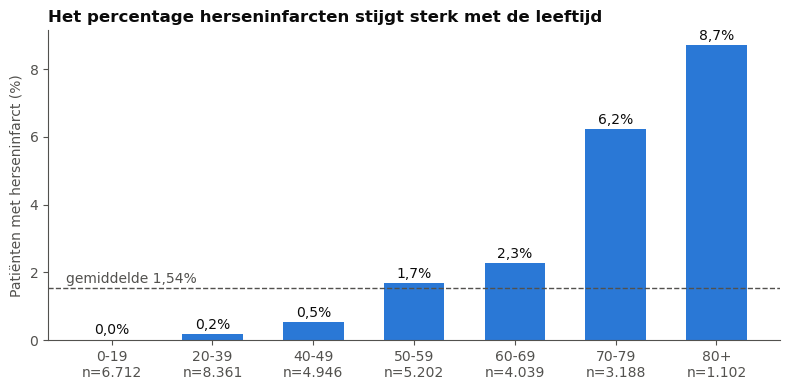

,n,herseninfarcten,percentage
age_group,,,
0-19,6712,1,0.01
20-39,8361,15,0.18
40-49,4946,27,0.55
50-59,5202,87,1.67
60-69,4039,92,2.28
70-79,3188,199,6.24
80+,1102,96,8.71


In [11]:
age_bins = [0, 20, 40, 50, 60, 70, 80, 90]
age_labels = ["0-19", "20-39", "40-49", "50-59", "60-69", "70-79", "80+"]
age_groups = pd.cut(train["age"], bins=age_bins, labels=age_labels,
                    right=False)
age_table = stroke_rate_table(train.assign(age_group=age_groups),
                              "age_group")

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(age_table.index.astype(str), age_table["percentage"],
              color=BLUE, width=0.6)
ax.axhline(BASE_RATE, color=MUTED, linewidth=1, linestyle="--")
ax.text(-0.45, BASE_RATE + 0.15, f"gemiddelde {nl(BASE_RATE, 2)}%",
        ha="left", color=MUTED)
for bar, (_, row) in zip(bars, age_table.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.15,
            f"{nl(row['percentage'])}%", ha="center", color=INK)
ax.set_xticks(range(len(age_table)))
ax.set_xticklabels([f"{label}\nn={n:,}".replace(",", ".")
                    for label, n in zip(age_table.index, age_table["n"])])
ax.set_ylabel("Patiënten met herseninfarct (%)")
ax.set_title("Het percentage herseninfarcten stijgt sterk met de leeftijd")
plt.tight_layout()
plt.show()
age_table.round(2)

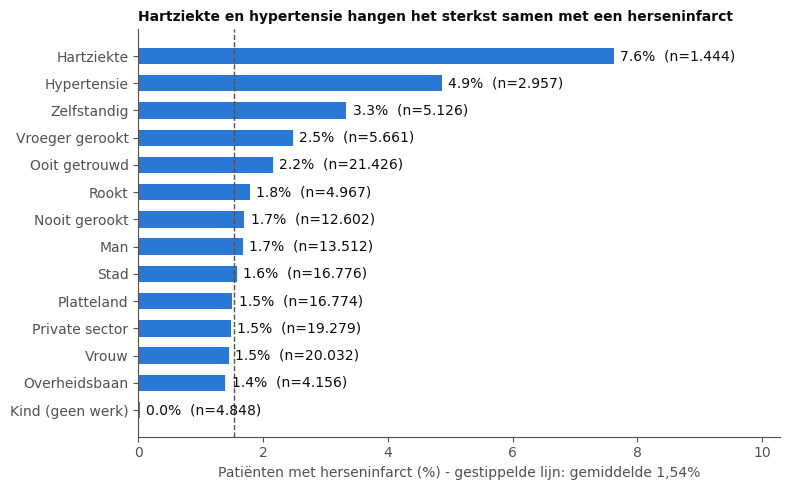

,n,herseninfarcten,percentage
Kind (geen werk),4848.0,1.0,0.02
Overheidsbaan,4156.0,58.0,1.40
Vrouw,20032.0,291.0,1.45
Private sector,19279.0,287.0,1.49
Platteland,16774.0,253.0,1.51
Stad,16776.0,264.0,1.57
Man,13512.0,226.0,1.67
Nooit gerookt,12602.0,214.0,1.70
Rookt,4967.0,89.0,1.79
Ooit getrouwd,21426.0,462.0,2.16


In [12]:
binary_features = {
    "heart_disease": "Hartziekte",
    "hypertension": "Hypertensie",
    "ever_married_Yes": "Ooit getrouwd",
    "work_type_Self-employed": "Zelfstandig",
    "smoking_status_formerly smoked": "Vroeger gerookt",
    "smoking_status_smokes": "Rookt",
    "smoking_status_never smoked": "Nooit gerookt",
    "gender_Male": "Man",
    "gender_Female": "Vrouw",
    "Residence_type_Urban": "Stad",
    "Residence_type_Rural": "Platteland",
    "work_type_Private": "Private sector",
    "work_type_Govt_job": "Overheidsbaan",
    "work_type_children": "Kind (geen werk)",
}


def binary_rate_table(data, features):
    """Percentage herseninfarcten voor patiënten met een 1 per kenmerk."""
    rows = {}
    for column, label in features.items():
        group = data[data[column].astype(bool)]
        rows[label] = {
            "n": len(group),
            "herseninfarcten": int(group["stroke"].sum()),
            "percentage": group["stroke"].mean() * 100,
        }
    return pd.DataFrame(rows).T.sort_values("percentage")


binary_table = binary_rate_table(train, binary_features)

fig, ax = plt.subplots(figsize=(8, 5))
positions = range(len(binary_table))
ax.barh(list(positions), binary_table["percentage"], color=BLUE,
        height=0.6)
ax.axvline(BASE_RATE, color=MUTED, linewidth=1, linestyle="--")
for position, (_, row) in zip(positions, binary_table.iterrows()):
    ax.text(row["percentage"] + 0.1, position,
            f"{nl(row['percentage'])}%  (n={int(row['n']):,})".replace(
                ",", "."), va="center", color=INK)
ax.set_yticks(list(positions))
ax.set_yticklabels(binary_table.index)
ax.set_xlim(0, binary_table["percentage"].max() * 1.35)
ax.set_xlabel("Patiënten met herseninfarct (%) - gestippelde lijn: "
              f"gemiddelde {nl(BASE_RATE, 2)}%")
ax.set_title("Hartziekte en hypertensie hangen het sterkst samen met een "
             "herseninfarct", fontsize=10)
plt.tight_layout()
plt.show()
binary_table.round(2)

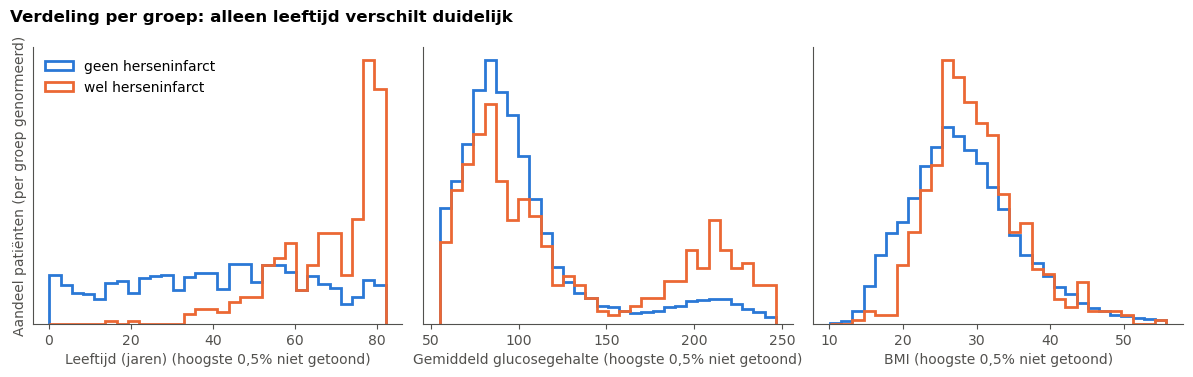

In [13]:
continuous_features = {
    "age": "Leeftijd (jaren)",
    "avg_glucose_level": "Gemiddeld glucosegehalte",
    "bmi": "BMI",
}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (column, label) in zip(axes, continuous_features.items()):
    upper = train[column].quantile(0.995)
    bins = np.linspace(train[column].min(), upper, 31)
    for value, color, name in [(0, BLUE, "geen herseninfarct"),
                               (1, ORANGE, "wel herseninfarct")]:
        ax.hist(train.loc[train["stroke"] == value, column], bins=bins,
                density=True, histtype="step", linewidth=2, color=color,
                label=name)
    ax.set_xlabel(label + " (hoogste 0,5% niet getoond)")
    ax.set_yticks([])
axes[0].set_ylabel("Aandeel patiënten (per groep genormeerd)")
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Verdeling per groep: alleen leeftijd verschilt duidelijk",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

In [14]:
correlations = (train.drop(columns="id").corr()["stroke"]
                .drop("stroke").sort_values(ascending=False))
correlations.round(3).to_frame("correlatie met stroke")

,correlatie met stroke
age,0.149
heart_disease,0.105
hypertension,0.084
avg_glucose_level,0.077
ever_married_Yes,0.066
work_type_Self-employed,0.062
smoking_status_formerly smoked,0.034
bmi,0.021
smoking_status_never smoked,0.010
gender_Male,0.009


De correlatie in de tabel is de Pearson-correlatie tussen een kenmerk en `stroke`. Bij een 0/1-kolom is dat de *punt-biseriële correlatie*. De waarde ligt tussen -1 en 1, waarbij 0 betekent dat er geen lineair verband is. Omdat de klasse zo klein is (1,54%), blijven alle correlaties laag. Ze zijn alleen bruikbaar voor het rangschikken van de kenmerken, niet als maat voor de voorspelbaarheid.

Een tweede vraag is of kenmerken onderling samenhangen, want dat kan het verband met `stroke` vertekenen. Dat wordt hieronder voor de belangrijkste kenmerken bekeken.

In [15]:
related = ["age", "ever_married_Yes", "work_type_children", "hypertension",
           "heart_disease", "avg_glucose_level", "bmi", "stroke"]
train[related].corr().round(2)

,age,ever_married_Yes,work_type_children,hypertension,heart_disease,avg_glucose_level,bmi,stroke
age,1.00,0.69,-0.64,0.27,0.24,0.23,0.36,0.15
ever_married_Yes,0.69,1.00,-0.55,0.18,0.12,0.15,0.34,0.07
work_type_children,-0.64,-0.55,1.00,-0.13,-0.09,-0.11,-0.46,-0.05
hypertension,0.27,0.18,-0.13,1.00,0.12,0.16,0.16,0.08
heart_disease,0.24,0.12,-0.09,0.12,1.00,0.14,0.06,0.10
avg_glucose_level,0.23,0.15,-0.11,0.16,0.14,1.00,0.19,0.08
bmi,0.36,0.34,-0.46,0.16,0.06,0.19,1.00,0.02
stroke,0.15,0.07,-0.05,0.08,0.10,0.08,0.02,1.00


## 1.6 Bevindingen uit de EDA

Alle getallen hieronder komen uit de tabellen en grafieken in paragraaf 1.5.

1. **Leeftijd is het sterkste kenmerk.** Het percentage herseninfarcten is bij 0-19 jaar bijna 0 en loopt op tot ruim 8% bij 80+ (zie de tabel bij de grafiek). De mediane leeftijd is 72 jaar bij patiënten met een herseninfarct en 43 jaar bij patiënten zonder. Leeftijd heeft ook de hoogste correlatie met `stroke` (0,149).
2. **Hartziekte en hypertensie verhogen het percentage sterk.** Met hartziekte heeft 7,6% een herseninfarct, zonder 1,3%. Met hypertensie is dat 4,9%, zonder 1,2%. Dat is ongeveer een factor 4 (hypertensie) tot 6 (hartziekte) hoger dan zonder.
3. **Een hoog glucosegehalte hangt samen met een herseninfarct.** Bij een gemiddelde glucose boven 200 heeft 5,1% een herseninfarct, bij 100 of lager 1,1%.
4. **BMI laat geen duidelijk verband zien.** Het percentage is het laagst bij ondergewicht (0,3%) maar verschilt daarboven weinig, en bij BMI boven 40 is het zelfs lager dan bij 25 tot 40. Dat past bij de lage correlatie (0,021).
5. **`ever_married_Yes` lijkt een sterk kenmerk (2,2% tegenover 0,5%) maar hangt vooral met leeftijd samen.** De correlatie tussen leeftijd en `ever_married_Yes` is 0,69. Het verband met `stroke` komt waarschijnlijk deels doordat getrouwde patiënten ouder zijn. Dit is een aanname uit de data en geen bewijs van oorzaak en gevolg.
6. **Kinderen krijgen vrijwel nooit een herseninfarct.** In de groep `work_type_children` (4.848 patiënten) is er maar één herseninfarct. Ook dit hangt samen met leeftijd (correlatie -0,64).
7. **Kenmerken zonder duidelijk verband:** geslacht, woonomgeving en `work_type_Private` liggen allemaal dicht bij het gemiddelde van 1,54%. Roken geeft een beperkt verschil: vroeger gerookt 2,5% en rookt 1,8%, tegenover nooit gerookt 1,7%.
8. **Kleine groepen.** `gender_Other` (6 patiënten) en `work_type_Never_worked` (141 patiënten) hebben geen enkel herseninfarct. Met zo weinig patiënten kan daar geen conclusie uit worden getrokken.
9. **Mogelijke uitschieters.** Er zijn 73 patiënten met een BMI boven 60 en 330 met een BMI onder 15. Zulke waarden zijn ongebruikelijk, maar kunnen voorkomen. Er is geen reden om ze te verwijderen: ze zijn niet aantoonbaar fout en de data heeft geen ontbrekende waarden (zie paragraaf 1.7).

**Gevolg voor de modellen.** Omdat de klasse zo klein is, zal een model dat altijd 'geen herseninfarct' voorspelt al 98,46% accuracy halen. Accuracy is daarom een slechte maat. De Kaggle-competitie en de tuning in deze notebook gebruiken de F1-score.

## 1.7 Data opschonen

Op basis van paragraaf 1.3 t/m 1.6 worden de volgende keuzes gemaakt.

| Probleem | Keuze | Onderbouwing |
|---|---|---|
| Ontbrekende waarden | Geen actie nodig | Er zijn 0 ontbrekende waarden in `train.csv` en `test.csv` (paragraaf 1.3 en 1.4). |
| Dubbele rijen | Geen actie nodig | Er zijn geen dubbele patiënten (paragraaf 1.4). |
| Kolom `id` | Verwijderen uit de features | Het is een volgnummer en geen kenmerk van de patiënt. De correlatie met `stroke` is 0,0007. Het `id` uit `test.csv` is wel nodig voor het Kaggle-bestand en wordt apart bewaard. |
| Overbodige dummy-kolommen | Per volledige groep één kolom verwijderen: `gender_Female`, `ever_married_No`, `work_type_Private` en `Residence_type_Rural` | Elke patiënt heeft in die groepen precies één 1, dus de verwijderde kolom is altijd af te leiden uit de rest (dummy trap, paragraaf 1.4). Bij KNN tellen twee complementaire kolommen bovendien dubbel mee in de afstand. |
| `smoking_status_*` | Alle drie de kolommen houden | De groep is niet volledig: 'unknown' heeft geen eigen kolom (paragraaf 1.4). Een kolom weghalen zou informatie kosten. |
| Uitschieters in `bmi` | Houden | Niet aantoonbaar fout. Een beslisboom wordt er niet door beïnvloed. Bij KNN wordt het effect beperkt door standaardisatie, maar niet weggenomen. |
| Datatype `bool` | Houden | Scikit-learn werkte zonder aanpassing (paragraaf 1.4). |

Welke kolom van een volledige groep wordt weggelaten maakt voor de informatie niets uit, omdat die altijd uit de andere kolommen van de groep af te leiden is.

In [16]:

ID_COLUMN = "id"
TARGET = "stroke"
REDUNDANT_DUMMIES = ["gender_Female", "ever_married_No",
                     "work_type_Private", "Residence_type_Rural"]
# CONTINUOUS wordt uitgebreid met de nieuwe interactie-kenmerken, zodat
# standaardisatie in paragraaf 1.9 ook deze schaalt.
CONTINUOUS = ["age", "avg_glucose_level", "bmi",
              "age_x_hypertension", "age_x_heart",
              "age_x_glucose"]


def clean_data(data):
    """Verwijder id en overbodige dummies, voeg risico-interacties toe.

    De drie interactie-kenmerken komen uit de EDA (paragraaf 1.5): oudere
    patiënten met hypertensie, hartziekte of een hoog glucosegehalte
    hebben samen een veel hoger infarctrisico dan optelsom van losse
    kenmerken. Door het product als nieuw kenmerk mee te geven, kan een
    lineair model die interactie expliciet leren (James et al., 2021,
    p. 88). `is_senior` vangt het drempeleffect bij 60+ jaar.
    """
    data = data.copy()
    data["age_x_hypertension"] = data["age"] * data["hypertension"]
    data["age_x_heart"] = data["age"] * data["heart_disease"]
    data["age_x_glucose"] = data["age"] * data["avg_glucose_level"] / 100
    data["is_senior"] = (data["age"] >= 60).astype(int)
    columns_to_drop = [ID_COLUMN] + REDUNDANT_DUMMIES
    return data.drop(columns=columns_to_drop)


train_clean = clean_data(train)
X = train_clean.drop(columns=TARGET)
y = train_clean[TARGET]
X_kaggle = clean_data(test)
test_ids = test[ID_COLUMN]

print("Features voor het trainen:", X.shape)
print("Features van test.csv voor Kaggle:", X_kaggle.shape)
print("Zelfde kolommen en volgorde:", list(X.columns) == list(
    X_kaggle.columns))
print("Nieuwe kenmerken:", [c for c in X.columns
                            if c.startswith("age_x") or c == "is_senior"])
print("Klassenverdeling (aandeel):")
print(y.value_counts(normalize=True).round(4))


Features voor het trainen: (33550, 20)
Features van test.csv voor Kaggle: (8388, 20)
Zelfde kolommen en volgorde: True
Nieuwe kenmerken: ['age_x_hypertension', 'age_x_heart', 'age_x_glucose', 'is_senior']
Klassenverdeling (aandeel):
stroke
0    0.9846
1    0.0154
Name: proportion, dtype: float64


## 1.8 Standaardisatie: wat en wanneer

**Wat.** Standaardiseren betekent dat een kenmerk wordt omgerekend naar een gemiddelde van 0 en een standaardafwijking van 1:

$$z = \frac{x - \mu}{\sigma}$$

Hierin is $\mu$ het gemiddelde en $\sigma$ de standaardafwijking van het kenmerk in de trainingsdata. In Scikit-learn doet `StandardScaler` dit (scikit-learn developers, n.d.-h).

**Waarom.** `age` loopt tot 82 en `avg_glucose_level` tot 282, terwijl een dummy-kolom alleen 0 of 1 is. Een model dat afstanden berekent (KNN) laat dan de kenmerken met de grootste getallen de afstand bepalen. Dit wordt in paragraaf 3.2 met echte patiënten laten zien.

**Wanneer wel en niet.**

- **KNN: wel.** De afstand tussen patiënten hangt af van de schaal van de kenmerken.
- **Decision Tree: niet nodig.** Een beslisboom vergelijkt één kenmerk per keer met een drempel (bijvoorbeeld `age <= 53,5`). Een lineaire omrekening verandert de volgorde van de patiënten niet, dus de boom komt op dezelfde splitsingen uit. Standaardiseren kan dus geen kwaad, maar helpt ook niet.
- **Alleen op de continue kolommen.** `age`, `avg_glucose_level` en `bmi` worden gestandaardiseerd. De 0/1-kolommen blijven zoals ze zijn: hun schaal (0 tot 1) is al vergelijkbaar met die van de gestandaardiseerde kolommen, en standaardiseren zou de waarden 0 en 1 vervangen door getallen die moeilijker te lezen zijn.

**Wanneer in de stappen.** Eerst de data splitsen in een trainingsdeel en een validatiedeel, daarna $\mu$ en $\sigma$ bepalen op het trainingsdeel alleen, en daarmee beide delen omrekenen. Als $\mu$ en $\sigma$ over alle data worden berekend, kijkt het model via het gemiddelde al naar de validatiedata. Dat heet *data leakage* en maakt de score onbetrouwbaar. Bij cross-validation geldt hetzelfde voor elke fold. Daarom zit de standaardisatie hieronder in een `Pipeline`, zodat deze per fold alleen op de trainingsfolds wordt gefit.

## 1.9 Standaardisatie uitvoeren

Eerst wordt de data gesplitst in 80% trainingsdata (`X_train`, `y_train`) en 20% validatiedata (`X_val`, `y_val`). De split is *gestratificeerd*, zodat beide delen 1,54% herseninfarcten hebben. `random_state=42` zorgt dat de split steeds hetzelfde is. De validatiedata wordt pas gebruikt om de uiteindelijke modellen te beoordelen. Het tunen gebeurt met cross-validation op `X_train`.

In [17]:
RANDOM_STATE = 42

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "- aandeel stroke:",
      round(y_train.mean(), 4))
print("Validatie:", X_val.shape, "- aandeel stroke:",
      round(y_val.mean(), 4))

Train: (26840, 20) - aandeel stroke: 0.0154
Validatie: (6710, 20) - aandeel stroke: 0.0154


In [18]:
def make_preprocessor():
    """Standaardiseer alleen de continue kolommen, laat de rest staan."""
    return ColumnTransformer(
        [("scale", StandardScaler(), CONTINUOUS)],
        remainder="passthrough",
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")


preprocessor = make_preprocessor()
X_train_scaled = preprocessor.fit_transform(X_train)  # fit alleen op train
X_val_scaled = preprocessor.transform(X_val)  # alleen transform

overview = pd.concat({
    "train voor": X_train[CONTINUOUS].agg(["mean", "std"]).T,
    "train na": X_train_scaled[CONTINUOUS].agg(["mean", "std"]).T,
    "validatie na": X_val_scaled[CONTINUOUS].agg(["mean", "std"]).T,
}, axis=1)
overview.round(3)

train voor         train na      validatie na       
                         mean     std     mean  std         mean    std
age                    41.901  22.497      0.0  1.0       -0.019  0.996
avg_glucose_level     103.670  42.207     -0.0  1.0       -0.010  0.991
bmi                    28.656   7.832      0.0  1.0       -0.035  0.968
age_x_hypertension      5.395  17.879     -0.0  1.0        0.003  0.999
age_x_heart             2.884  13.868      0.0  1.0        0.009  1.020
age_x_glucose          45.658  36.546      0.0  1.0       -0.021  0.975

**Controle.** Na de standaardisatie zijn het gemiddelde en de standaardafwijking van de trainingsdata 0 en 1. In de validatiedata zijn ze dat bijna maar niet precies: de omrekening gebruikt $\mu$ en $\sigma$ van de trainingsdata en niet die van de validatiedata. Dat is bedoeld en laat zien dat er geen informatie uit de validatiedata is gebruikt. De 0/1-kolommen zijn ongewijzigd.

In [19]:
# Controle dat de dummy-kolommen niet zijn veranderd
dummy_columns = [c for c in X_train.columns if c not in CONTINUOUS]
print("Dummy-kolommen ongewijzigd:",
      X_train_scaled[dummy_columns].equals(X_train[dummy_columns]))

Dummy-kolommen ongewijzigd: True


# 2. Evaluatie van een classificatiemodel

In dit hoofdstuk wordt Opdracht 2 uitgewerkt. Opdracht 2 vraagt om uit te leggen (1) met welke metrics een classificatiemodel wordt beoordeeld, (2) hoe elke metric wordt berekend met behulp van een confusion matrix en (3) waarom de F1-score passend is voor deze dataset.

Om deze punten concreet te maken wordt één zelfgekozen model getoond: een eenvoudige **Decision Tree** zonder hyperparameter-tuning en zonder techniek voor de scheve klassenverdeling. Dit model is gekozen omdat het snel traint, geen standaardisatie nodig heeft (paragraaf 1.8) en de problemen van een onbewerkt model op een scheve dataset goed laat zien. De tuning en balanceertechnieken komen pas aan bod in de modelhoofdstukken (Opdracht 3).

**Welke data wordt gebruikt?** Alle metrics in dit hoofdstuk komen uit de validatieset (`X_val`, `y_val`) uit paragraaf 1.9 dus niet uit cross-validation. Dit zijn 20% van de patiënten uit `train.csv` die het model tijdens het trainen niet heeft gezien. `test.csv` wordt bewust niet gebruikt: daar ontbreekt de kolom `stroke`, dus daar kunnen geen metrics mee worden berekend (Kaggle, 2026).

## 2.1 Welke metrics beoordelen een classificatiemodel?

Voor een binaire classificatietaak (herseninfarct ja/nee) worden vier metrics gebruikt (scikit-learn developers, n.d.-i):

- **Accuracy** — het aandeel correcte voorspellingen (zowel positief als negatief).
- **Precision** — van alle patiënten die het model als 'infarct' voorspelt, hoeveel procent heeft dat ook echt?
- **Recall**  — van alle patiënten die echt een infarct hebben, hoeveel procent vindt het model?
- **F1-score** — het harmonisch gemiddelde van precision en recall; een maat die beide tegelijk belangrijk vindt.

Elke metric kijkt op een andere manier naar het model. Bij een scheve klassenverdeling (zoals in deze dataset) laten ze heel verschillende dingen zien. Dat wordt in paragraaf 2.5 verder uitgewerkt.

## 2.2 De confusion matrix

Een confusion matrix (verwarringsmatrix) is een tabel met 2 rijen en 2 kolommen die alle vier mogelijke uitkomsten telt (scikit-learn developers, n.d.-j):

|                          | Voorspeld: geen infarct | Voorspeld: infarct |
|--------------------------|------------------------|--------------------|
| **Echt: geen infarct**   | True Negative (TN)     | False Positive (FP) |
| **Echt: infarct**        | False Negative (FN)    | True Positive (TP)  |

- **TN** — patiënt heeft geen infarct en wordt juist voorspeld als 'geen infarct'.
- **TP** — patiënt heeft een infarct en wordt juist voorspeld als 'infarct'.
- **FP** — patiënt heeft geen infarct maar wordt onterecht voorspeld als 'infarct' (vals alarm).
- **FN** — patiënt heeft wel een infarct maar wordt gemist door het model.

Voor een medische toepassing zoals bij MedPredict weegt een FN zwaar: een gemiste patiënt krijgt geen preventieve zorg. Een FP betekent een vals alarm en bijvoorbeeld een extra controle.

## 2.3 Het zelfgekozen model trainen

Voor Opdracht 2 wordt een `DecisionTreeClassifier` met `max_depth=3` getraind op `X_train` en `y_train`. Hyperparameter-tuning en technieken voor de scheve klassenverdeling worden hier bewust niet toegepast, die komen in de latere hoofdstukken. Zo laat dit model goed zien hoe een onbewerkt model op een scheve dataset presteert.

De variabelen `X_train`, `X_val`, `y_train`, `y_val` en `RANDOM_STATE` komen uit paragraaf 1.9 (cel 28). `DecisionTreeClassifier` en `ConfusionMatrixDisplay` zijn in de importcel bovenaan al geïmporteerd; `accuracy_score` en `confusion_matrix` worden hieronder extra geïmporteerd.

In [20]:
# Eenvoudig Decision Tree-model voor Opdracht 2 (evaluatie-demonstratie).

eval_tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
eval_tree.fit(X_train, y_train)
y_pred_eval = eval_tree.predict(X_val)

print("Aantal patiënten in validatieset:", len(y_pred_eval))
print("Aantal keer 'infarct' voorspeld:", int(y_pred_eval.sum()))
print("Aantal keer 'infarct' werkelijk:", int(y_val.sum()))

Aantal patiënten in validatieset: 6710
Aantal keer 'infarct' voorspeld: 0
Aantal keer 'infarct' werkelijk: 103


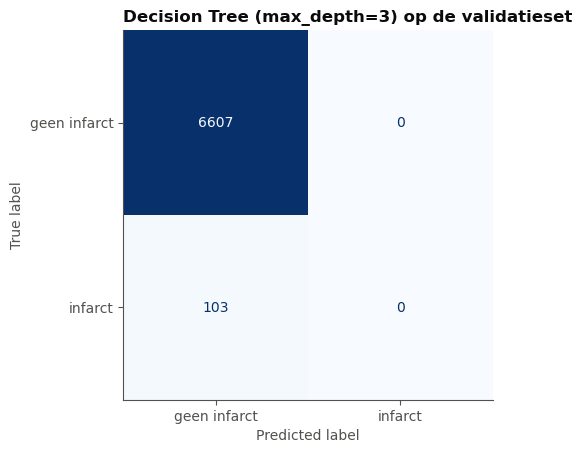

In [21]:

# Confusion matrix tonen op de validatieset (geen cross-validation).
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred_eval,
    display_labels=["geen infarct", "infarct"],
    cmap="Blues", colorbar=False)
plt.title("Decision Tree (max_depth=3) op de validatieset")
plt.show()

In [22]:

# Haal de vier getallen uit de confusion matrix voor gebruik in de formules.
cm_eval = confusion_matrix(y_val, y_pred_eval)
tn, fp, fn, tp = cm_eval.ravel()
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")

TN = 6607, FP = 0, FN = 103, TP = 0


## 2.4 Hoe wordt elke metric berekend?

Uit de getallen van de confusion matrix (zie de uitvoer van de vorige cel) volgen de vier metrics als volgt (scikit-learn developers, n.d.-i).

**Accuracy** telt alle juiste voorspellingen (TP + TN) gedeeld door het totaal aantal patiënten:

$$\text{accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

**Precision** kijkt alleen naar de patiënten die het model als 'infarct' voorspelt:

$$\text{precision} = \frac{TP}{TP + FP}$$

**Recall** (sensitiviteit) kijkt alleen naar de patiënten die echt een infarct hebben:

$$\text{recall} = \frac{TP}{TP + FN}$$

**F1-score** is het harmonisch gemiddelde van precision en recall:

$$F1 = 2 \cdot \frac{\text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}$$

Het harmonisch gemiddelde is laag als een van beide waarden laag is. Een model met hoge precision maar recall = 0 krijgt F1 = 0, en andersom. Dit maakt F1 streng voor modellen die één van beide verwaarlozen.

In [23]:
# Bereken de vier metrics handmatig uit TN/FP/FN/TP én met Scikit-learn,
# zodat je kunt controleren dat beide manieren dezelfde uitkomsten geven.

def manual_metrics(tn, fp, fn, tp):
    """Bereken accuracy, precision, recall en F1 uit de CM-getallen."""
    total = tn + fp + fn + tp
    accuracy = (tp + tn) / total
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    if (precision + recall) > 0:
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = 0.0
    return {"accuracy": accuracy, "precision": precision,
            "recall": recall, "F1": f1}


by_hand = manual_metrics(tn, fp, fn, tp)
by_sklearn = {
    "accuracy": accuracy_score(y_val, y_pred_eval),
    "precision": precision_score(y_val, y_pred_eval, zero_division=0),
    "recall": recall_score(y_val, y_pred_eval),
    "F1": f1_score(y_val, y_pred_eval),
}
pd.DataFrame({"handmatig": by_hand, "sklearn": by_sklearn}).round(4)

,handmatig,sklearn
accuracy,0.9846,0.9846
precision,0.0000,0.0000
recall,0.0000,0.0000
F1,0.0000,0.0000


## 2.5 Waarom de F1-score en waarom accuracy misleidend is

De dataset is **sterk scheef (imbalanced)**: slechts 1,54% van de patiënten heeft een herseninfarct (paragraaf 1.3). Dit heeft grote gevolgen voor de keuze van de evaluatiemetriek.

**Accuracy is misleidend bij een scheve klasse.** Een model dat voor élke patiënt 'geen infarct' voorspelt, krijgt automatisch een accuracy gelijk aan het aandeel van de meerderheidsklasse, ongeveer 98,46% zonder dat het ook maar één patiënt met een infarct herkent. Een hoge accuracy zegt dus niets over het nut van het model voor de medische toepassing (Hossin & Sulaiman, 2015).

**F1-score let op precision én recall.** F1 is pas hoog als het model zowel patiënten met een infarct opspoort (recall) als weinig valse alarmen afgeeft (precision). Een triviaal model dat alles op 0 zet, krijgt automatisch F1 = 0, omdat de recall 0 is. Daarom is F1 een realistischere maat voor een scheve dataset en wordt F1 ook door Kaggle als beoordelingsmaat gekozen (Kaggle, 2026).

De cel hieronder laat dit concreet zien door een `DummyClassifier` te vergelijken met de Decision Tree uit paragraaf 2.3.

In [24]:
# Triviaal model dat voor elke patiënt de meerderheidsklasse (0) voorspelt.
# Hiermee is te zien dat accuracy hoog kan zijn terwijl F1 nul is.

dummy = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_val)

dummy_metrics = {
    "accuracy": accuracy_score(y_val, y_pred_dummy),
    "precision": precision_score(y_val, y_pred_dummy, zero_division=0),
    "recall": recall_score(y_val, y_pred_dummy),
    "F1": f1_score(y_val, y_pred_dummy),
}

pd.DataFrame({
    "Decision Tree (max_depth=3)": by_hand,
    "Dummy (altijd 0)": dummy_metrics,
}).round(4)

,Decision Tree (max_depth=3),Dummy (altijd 0)
accuracy,0.9846,0.9846
precision,0.0000,0.0000
recall,0.0000,0.0000
F1,0.0000,0.0000


**Interpretatie.** De tabel laat zien waarom accuracy op deze dataset misleidend is: het dummy-model doet niets zinvols maar scoort toch hoog op accuracy. De F1-score van 0 verraadt direct dat dit model geen enkele patiënt met een infarct herkent. Voor MedPredict is dat onbruikbaar: het doel is nu juist patiënten met een verhoogd risico opsporen. Daarom wordt in de rest van het notebook F1 gebruikt als hoofdmaat, zowel in de cross-validation als op de validatieset, in lijn met de keuze van Kaggle (Kaggle, 2026).


# 3. K-Nearest Neighbors (KNN)

## 3.1 Hoe werkt KNN?

KNN voorspelt de klasse van een nieuwe patiënt door te kijken naar de $k$ patiënten in de trainingsdata die er het meest op lijken, de *buren*. De meest voorkomende klasse onder die buren wordt de voorspelling. Het aandeel buren met een herseninfarct kan ook als kans worden gebruikt. Er is geen trainingsfase waarin een formule wordt geleerd: het model onthoudt de trainingsdata en rekent pas bij een voorspelling (scikit-learn developers, n.d.-f).

*Lijken op elkaar* wordt gemeten met een afstand tussen twee patiënten $x$ en $y$ met $n$ kenmerken:

- **Euclidische afstand:** $d(x, y) = \sqrt{\sum_{i=1}^{n} (x_i - y_i)^2}$. Dit is de rechte lijn tussen twee punten.
- **Manhattan-afstand:** $d(x, y) = \sum_{i=1}^{n} |x_i - y_i|$. Dit is de som van de verschillen per kenmerk, als een route langs de rasterlijnen van een stad.
- Beide zijn varianten van de Minkowski-afstand met parameter $p$: $p = 1$ geeft Manhattan en $p = 2$ geeft Euclidisch (scikit-learn developers, n.d.-e).

Hieronder wordt dit uitgerekend voor drie echte patiënten uit de gestandaardiseerde trainingsdata, en vergeleken met Scikit-learn.

In [25]:
example = X_train_scaled[["age", "avg_glucose_level", "bmi",
                          "hypertension", "heart_disease"]].iloc[:3]
patient_a, patient_b, patient_c = example.to_numpy()

euclid_ab = np.sqrt(((patient_a - patient_b) ** 2).sum())
manhattan_ab = np.abs(patient_a - patient_b).sum()
euclid_ac = np.sqrt(((patient_a - patient_c) ** 2).sum())

print(example.round(2))
print()
print(f"Euclidisch A-B (zelf):   {euclid_ab:.4f}")
print(f"Euclidisch A-B (sklearn): "
      f"{euclidean_distances(example)[0, 1]:.4f}")
print(f"Manhattan A-B (zelf):    {manhattan_ab:.4f}")
print(f"Manhattan A-B (sklearn):  "
      f"{manhattan_distances(example)[0, 1]:.4f}")
print(f"Euclidisch A-C (zelf):   {euclid_ac:.4f}")

        age  avg_glucose_level   bmi  hypertension  heart_disease
17889  0.36              -0.65  2.18             0              0
10031  0.09              -0.23  1.50             0              0
5985  -0.75               0.24 -0.34             0              0

Euclidisch A-B (zelf):   0.8401
Euclidisch A-B (sklearn): 0.8401
Manhattan A-B (zelf):    1.3638
Manhattan A-B (sklearn):  1.3638
Euclidisch A-C (zelf):   2.8891


De eigen berekening en Scikit-learn geven dezelfde afstand. In de uitvoer ligt patiënt B dichter bij patiënt A dan patiënt C. Het verschil tussen de twee afstanden: Euclidisch straft een groot verschil op één kenmerk zwaarder (door het kwadraat) dan Manhattan, waar alle verschillen even zwaar meetellen.

## 3.2 Waarom standaardiseren bij KNN?

De afstand is een som over alle kenmerken. Een kenmerk met grote getallen levert grotere verschillen en bepaalt daardoor de afstand. Hieronder staat, gemiddeld over 5.000 willekeurige paren patiënten uit `X_train`, hoeveel elk kenmerk bijdraagt aan de kwadratische Euclidische afstand, eerst met de originele waarden en daarna na standaardisatie.

In [26]:
rng = np.random.default_rng(RANDOM_STATE)
first_index = rng.integers(0, len(X_train), 5000)
second_index = rng.integers(0, len(X_train), 5000)


def mean_contribution(frame):
    values = frame.to_numpy(dtype=float)
    squared = (values[first_index] - values[second_index]) ** 2
    return pd.Series(squared.mean(axis=0) / squared.mean(axis=0).sum() * 100,
                     index=frame.columns)


pair_contribution = pd.DataFrame({
    "origineel_%": mean_contribution(X_train),
    "gestandaardiseerd_%": mean_contribution(X_train_scaled),
}).round(1)
pair_contribution.sort_values("origineel_%", ascending=False)

,origineel_%,gestandaardiseerd_%
avg_glucose_level,42.2,12.6
age_x_glucose,32.3,12.9
age,12.2,12.8
age_x_hypertension,7.2,11.9
age_x_heart,4.7,13.1
bmi,1.4,12.5
Residence_type_Urban,0.0,3.2
smoking_status_formerly smoked,0.0,1.7
work_type_Self-employed,0.0,1.6
work_type_Never_worked,0.0,0.1


Zonder standaardisatie bepalen `avg_glucose_level` en `age` samen bijna de hele afstand, en tellen `bmi` en alle 0/1-kolommen (waaronder `hypertension` en `heart_disease`, die sterk met een herseninfarct samenhangen) nauwelijks mee. Na standaardisatie leveren de drie continue kenmerken elk ongeveer een vijfde van de afstand en doen de 0/1-kolommen weer mee.

Ook de 0/1-kolommen beïnvloeden de afstand: een verschil in een dummy-kolom is 1, wat ongeveer één standaardafwijking van een gestandaardiseerd kenmerk is. Daarom zijn de overbodige complementaire dummy-kolommen verwijderd (paragraaf 1.7): anders zou bijvoorbeeld `ever_married_Yes` dubbel meetellen.

## 3.3 Hyperparameters en regularisatie van KNN

| Hyperparameter | Betekenis | Effect |
|---|---|---|
| `n_neighbors` ($k$) | Aantal buren dat meestemt | Klein $k$: het model volgt elk detail van de trainingsdata (overfitting). Groot $k$: het model wordt vlakker (underfitting). |
| `weights` | `uniform`: alle buren tellen gelijk. `distance`: dichtbij tellen zwaarder | `distance` maakt het model gevoeliger voor de dichtstbijzijnde buren. |
| `p` (of `metric`) | 1 = Manhattan, 2 = Euclidisch | Bepaalt hoe afstand wordt gemeten. Welke van de twee het best werkt wordt getuned. |

**Regularisatie.** Bij modellen als Logistic Regression is regularisatie een straf op grote gewichten in de verliesfunctie. KNN heeft geen gewichten en geen verliesfunctie, dus een parameter zoals `C` of `alpha` bestaat niet. De enige manier om de complexiteit te beperken is een groter $k$: dat middelt over meer patiënten en maakt de voorspelling stabieler. Dit is mijn interpretatie van de vraag. Of dit is wat de docent bedoelt moet nog worden bevestigd.

## 3.4 Opzet van de evaluatie

Voor KNN en de Decision Tree (hoofdstuk 4) wordt dezelfde opzet gebruikt, zodat de resultaten vergelijkbaar zijn:

- **Pipeline:** standaardisatie, eventueel een techniek voor de scheve klassenverdeling en het model zitten in één `Pipeline` van `imbalanced-learn` (Lemaître et al., 2017). Daardoor worden standaardisatie en resampling in elke cross-validation-fold alleen op de trainingsfolds uitgevoerd. De resampling wordt dus nooit op de validatiefold toegepast, wat bij het vooraf oversamplen van de hele trainingsset wel gebeurt (data leakage).
- **Tuning:** `GridSearchCV` met gestratificeerde 5-voudige cross-validation op `X_train` en de F1-score als maat. F1 is het harmonisch gemiddelde van precision en recall, $F_1 = 2 \cdot \frac{\text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}$, en is de maat van de Kaggle-competitie. Accuracy is hier ongeschikt (paragraaf 1.6).
- **Beslissingsdrempel:** een model geeft een kans en voorspelt 'herseninfarct' bij een kans boven 0,5. Bij zo'n kleine klasse is 0,5 vaak niet de beste drempel voor F1. De beste drempel wordt daarom bepaald op voorspellingen uit de cross-validation op `X_train` (`cross_val_predict`), dus zonder de validatiedata te gebruiken.
- **Beoordeling:** het gekozen model wordt eenmalig beoordeeld op `X_val`, die tijdens het tunen niet is gebruikt.

In [27]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def make_pipeline(model, sampler=None):
    """Bouw preprocessing, optionele resampling en model in één pipeline."""
    steps = [("prep", make_preprocessor())]
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps.append(("model", model))
    return Pipeline(steps)


def tune(pipeline, param_grid, X_data, y_data, train_score=False):
    """Zoek de beste hyperparameters met F1 en gestratificeerde CV."""
    search = GridSearchCV(pipeline, param_grid, scoring="f1", cv=CV,
                          n_jobs=-1, return_train_score=train_score)
    return search.fit(X_data, y_data)


def best_threshold(y_true, probabilities):
    """Geef de drempel met de hoogste F1 en die F1."""
    precision, recall, thresholds = precision_recall_curve(y_true,
                                                           probabilities)
    f1_values = 2 * precision * recall / (precision + recall + 1e-12)
    index = np.argmax(f1_values[:-1])
    return thresholds[index], f1_values[index]


def cv_threshold(estimator, X_data, y_data):
    """Bepaal de beste drempel uit CV-voorspellingen op de trainingsdata."""
    probabilities = cross_val_predict(estimator, X_data, y_data, cv=CV,
                                      method="predict_proba",
                                      n_jobs=-1)[:, 1]
    return best_threshold(y_data, probabilities)


def evaluate(estimator, X_data, y_data, threshold=0.5):
    """Bereken F1, precision en recall bij een gegeven drempel."""
    predicted = estimator.predict_proba(X_data)[:, 1] >= threshold
    return {
        "drempel": round(float(threshold), 3),
        "F1": round(f1_score(y_data, predicted), 4),
        "precision": round(precision_score(y_data, predicted,
                                           zero_division=0), 4),
        "recall": round(recall_score(y_data, predicted), 4),
        "voorspeld_positief": int(predicted.sum()),
    }


def top_results(search, columns, n=5):
    """Toon de beste parametercombinaties van een GridSearchCV."""
    results = pd.DataFrame(search.cv_results_)
    results = results.sort_values("rank_test_score").head(n)
    table = results[columns + ["mean_test_score", "std_test_score"]]
    return table.rename(columns={
        "mean_test_score": "F1_cv", "std_test_score": "std_cv"}).round(4)

## 3.5 Tuning zonder techniek voor de scheve klassen

Eerst wordt KNN afgesteld zonder techniek voor de scheve klassenverdeling. Dit is de vergelijkingsbasis voor de twee technieken in paragraaf 3.6. Het raster bevat de drie hyperparameters uit paragraaf 3.3.

In [28]:
knn_grid = {
    "model__n_neighbors": [5, 11, 21, 41, 81, 161],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2],
}

knn_plain = tune(make_pipeline(KNeighborsClassifier()), knn_grid,
                 X_train, y_train, train_score=True)
print("Beste parameters:", knn_plain.best_params_)
print("Beste F1 (CV):", round(knn_plain.best_score_, 4))
top_results(knn_plain, ["param_model__n_neighbors",
                        "param_model__weights", "param_model__p"])

Exception ignored in: <function ResourceTracker.__del__ at 0x106d3dc60>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
/opt/anaconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Exception ignored in: <function ResourceTracker.__del__ at 0x106f99c60>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  F

Beste parameters: {'model__n_neighbors': 5, 'model__p': 1, 'model__weights': 'distance'}
Beste F1 (CV): 0.0133


,param_model__n_neighbors,param_model__weights,param_model__p,F1_cv,std_cv
1,5,distance,1,0.0133,0.0109
0,5,uniform,1,0.0092,0.0113
2,5,uniform,2,0.0092,0.0184
3,5,distance,2,0.0090,0.0180
21,161,distance,1,0.0000,0.0000


### Overfitting en underfitting bij KNN

De grafiek laat de F1 op de trainingsfolds en op de validatiefolds zien voor verschillende waarden van $k$. Is de F1 op de trainingsfolds veel hoger dan op de validatiefolds, dan past het model zich te veel aan de trainingsdata aan (overfitting). Zijn beide laag, dan is het model te simpel (underfitting). De grafiek is gemaakt met `weights="uniform"`. Bij `weights="distance"` is elke trainingspatiënt zijn eigen dichtstbijzijnde buur op afstand 0 en krijgt daardoor alle gewicht, dus de F1 op de trainingsfolds is dan altijd 1 en zegt niets.

Exception ignored in: <function ResourceTracker.__del__ at 0x1075e9c60>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


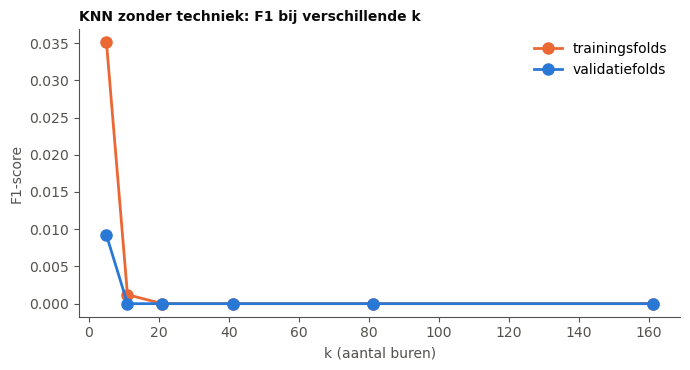

In [29]:
def plot_k_curve(search, title):
    """Plot F1 op train en validatie tegen k (beste overige parameters)."""
    results = pd.DataFrame(search.cv_results_)
    best = search.best_params_
    mask = ((results["param_model__weights"] == "uniform") &
            (results["param_model__p"] == best["model__p"]))
    subset = results[mask].sort_values("param_model__n_neighbors")
    ks = subset["param_model__n_neighbors"].astype(int)
    fig, ax = plt.subplots(figsize=(7, 3.8))
    ax.plot(ks, subset["mean_train_score"], color=ORANGE, linewidth=2,
            marker="o", markersize=8, label="trainingsfolds")
    ax.plot(ks, subset["mean_test_score"], color=BLUE, linewidth=2,
            marker="o", markersize=8, label="validatiefolds")
    ax.set_xlabel("k (aantal buren)")
    ax.set_ylabel("F1-score")
    ax.set_title(title, fontsize=10)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()


plot_k_curve(knn_plain, "KNN zonder techniek: F1 bij verschillende k")

## 3.6 Twee technieken voor de scheve klassenverdeling

Slechts 1,54% van de patiënten heeft een herseninfarct. Een KNN-model heeft dan bij de meeste patiënten vooral buren zonder herseninfarct en voorspelt zelden de kleine klasse. Twee technieken om dit aan te pakken:

**1. SMOTE (oversampling).** SMOTE maakt kunstmatige patiënten met een herseninfarct. Voor een patiënt $x_i$ uit de kleine klasse wordt een van zijn buren $x_{nn}$ uit dezelfde klasse gekozen, en een nieuwe patiënt ligt op de lijn ertussen: $x_{nieuw} = x_i + \lambda (x_{nn} - x_i)$ met $\lambda$ een willekeurig getal tussen 0 en 1 (Chawla et al., 2002). Hierdoor wordt de kleine klasse groter zonder dat dezelfde rijen worden gekopieerd. Een nadeel hier: SMOTE interpoleert ook de 0/1-kolommen, waardoor kunstmatige patiënten waarden als 0,4 kunnen krijgen in een dummy-kolom.

**2. RandomUnderSampler (undersampling).** Willekeurig patiënten uit de grote klasse weggooien, tot de klassen meer in balans zijn. Voordeel is een kleinere trainingsset en snellere KNN. Nadeel is dat informatie van de weggegooide patiënten verloren gaat.

Bij beide technieken is `sampling_strategy` een hyperparameter: de verhouding tussen de kleine en de grote klasse na het resamplen (1,0 is gelijk, 0,1 is één op tien). Die wordt mee getuned. Beide worden alleen op de trainingsfolds toegepast, omdat ze in de pipeline zitten.

In [30]:
knn_sampler_grid = {
    "model__n_neighbors": [31, 81, 161],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2],
    "sampler__sampling_strategy": [0.1, 0.3, 1.0],
}

knn_smote = tune(
    make_pipeline(KNeighborsClassifier(),
                  SMOTE(random_state=RANDOM_STATE)),
    knn_sampler_grid, X_train, y_train)
knn_under = tune(
    make_pipeline(KNeighborsClassifier(),
                  RandomUnderSampler(random_state=RANDOM_STATE)),
    knn_sampler_grid, X_train, y_train)

grid_columns = ["param_model__n_neighbors", "param_model__weights",
                "param_model__p", "param_sampler__sampling_strategy"]
print("SMOTE:", knn_smote.best_params_)
print("RandomUnderSampler:", knn_under.best_params_)
top_results(knn_smote, grid_columns, n=3)

SMOTE: {'model__n_neighbors': 161, 'model__p': 1, 'model__weights': 'distance', 'sampler__sampling_strategy': 0.3}
RandomUnderSampler: {'model__n_neighbors': 161, 'model__p': 1, 'model__weights': 'distance', 'sampler__sampling_strategy': 0.3}


,param_model__n_neighbors,param_model__weights,param_model__p,param_sampler__sampling_strategy,F1_cv,std_cv
28,161,distance,1,0.3,0.1264,0.0147
25,161,uniform,1,0.3,0.1227,0.0141
31,161,uniform,2,0.3,0.1223,0.0138


In [31]:
top_results(knn_under, grid_columns, n=3)

,param_model__n_neighbors,param_model__weights,param_model__p,param_sampler__sampling_strategy,F1_cv,std_cv
28,161,distance,1,0.3,0.1444,0.0324
34,161,distance,2,0.3,0.1378,0.0289
25,161,uniform,1,0.3,0.1366,0.0371


## 3.7 Beoordeling van KNN

Voor elk van de drie modellen wordt de beste drempel bepaald met cross-validation op `X_train`. Daarna worden de modellen beoordeeld op `X_val`. Zo ziet de validatiedata geen enkel stuk van het tunen. De keuze van het uiteindelijke model gebeurt op basis van de F1 uit de cross-validation en niet op basis van `X_val`.

In [32]:
knn_models = {
    "KNN zonder techniek": knn_plain,
    "KNN + SMOTE": knn_smote,
    "KNN + RandomUnderSampler": knn_under,
}

knn_rows = {}
knn_thresholds = {}
for name, search in knn_models.items():
    threshold, f1_cv = cv_threshold(search.best_estimator_, X_train, y_train)
    knn_thresholds[name] = threshold
    on_val_default = evaluate(search.best_estimator_, X_val, y_val)
    on_val_tuned = evaluate(search.best_estimator_, X_val, y_val, threshold)
    knn_rows[name] = {
        "F1_cv_drempel_0.5": round(search.best_score_, 4),
        "F1_cv_beste_drempel": round(f1_cv, 4),
        "beste_drempel": round(threshold, 3),
        "F1_val_drempel_0.5": on_val_default["F1"],
        "F1_val_beste_drempel": on_val_tuned["F1"],
        "precision_val": on_val_tuned["precision"],
        "recall_val": on_val_tuned["recall"],
    }
pd.DataFrame(knn_rows).T

,F1_cv_drempel_0.5,F1_cv_beste_drempel,beste_drempel,F1_val_drempel_0.5,F1_val_beste_drempel,precision_val,recall_val
KNN zonder techniek,0.0133,0.0728,0.111,0.0177,0.0687,0.0428,0.1748
KNN + SMOTE,0.1264,0.1273,0.497,0.1195,0.1178,0.0681,0.4369
KNN + RandomUnderSampler,0.1444,0.1445,0.497,0.1273,0.1340,0.0912,0.2524


## 3.8 Kaggle-inzending voor KNN

Het gekozen model wordt opnieuw gefit op de volledige `train.csv` (trainings- en validatiedeel samen), met de beste hyperparameters en de beste drempel uit paragraaf 3.7. Daarmee worden de patiënten in `test.csv` voorspeld. Het bestand heeft de kolommen `id` en `stroke`, net als `sample_submission.csv`.

In [33]:
sample_submission = pd.read_csv("sample_submission.csv")


def make_submission(search, threshold, file_name):
    """Fit op alle trainingsdata en schrijf het Kaggle-bestand weg."""
    final_model = clone(search.best_estimator_).fit(X, y)
    predicted = final_model.predict_proba(X_kaggle)[:, 1] >= threshold
    submission = pd.DataFrame({"id": test_ids,
                               "stroke": predicted.astype(int)})
    assert list(submission.columns) == list(sample_submission.columns)
    assert set(submission["id"]) == set(sample_submission["id"])
    assert len(submission) == len(sample_submission)
    submission.to_csv(file_name, index=False)
    return submission


knn_choice = max(knn_rows, key=lambda name: knn_rows[name][
    "F1_cv_beste_drempel"])
print("Gekozen KNN-model (hoogste F1 in CV):", knn_choice)
knn_submission = make_submission(knn_models[knn_choice],
                                 knn_thresholds[knn_choice],
                                 "submission_knn.csv")
print("Aantal rijen:", len(knn_submission))
print("Voorspeld herseninfarct:", int(knn_submission["stroke"].sum()),
      f"({knn_submission['stroke'].mean():.2%}) - in train is dat "
      f"{y.mean():.2%}")
knn_submission.head()

Gekozen KNN-model (hoogste F1 in CV): KNN + RandomUnderSampler
Aantal rijen: 8388
Voorspeld herseninfarct: 442 (5.27%) - in train is dat 1.54%


,id,stroke
0,32840,0
1,45158,0
2,56105,0
3,3112,0
4,35224,0


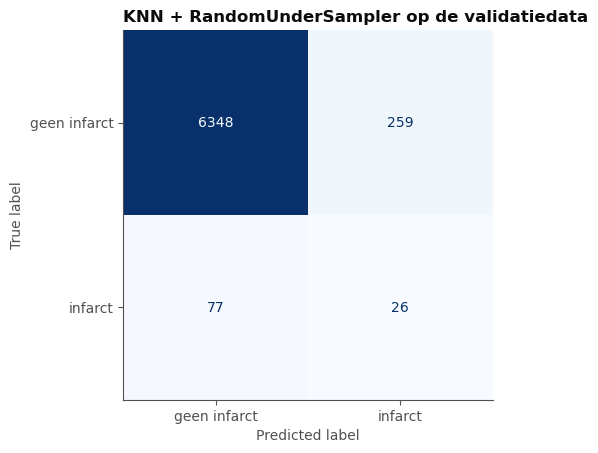

In [34]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    knn_models[knn_choice].best_estimator_.predict_proba(X_val)[:, 1]
    >= knn_thresholds[knn_choice],
    display_labels=["geen infarct", "infarct"], cmap="Blues",
    colorbar=False)
plt.title(f"{knn_choice} op de validatiedata")
plt.show()

# 4. Decision Tree

## 4.1 Hoe werkt een Decision Tree?

Een beslisboom stelt een reeks ja/nee-vragen over de kenmerken van een patiënt, bijvoorbeeld 'is `heart_disease` gelijk aan 1?' of 'is `age` kleiner dan of gelijk aan 53,5?'. Elke vraag is een *knoop*, elk antwoord een *tak*, en aan het einde staat een *blad* met een voorspelling: de meest voorkomende klasse van de trainingspatiënten in dat blad (scikit-learn developers, n.d.-a). De boom wordt gebouwd door telkens de vraag (kenmerk en drempel) te kiezen die de patiënten het best in groepen met dezelfde klasse verdeelt. Dat gebeurt tot een stopcriterium is bereikt.

## 4.2 Splitscriteria: Gini en entropie

Hoe zuiver een knoop is, wordt gemeten met een *onzuiverheidsmaat*. Met $p_k$ het aandeel patiënten van klasse $k$ in de knoop:

- **Gini:** $G = 1 - \sum_k p_k^2$
- **Entropie:** $H = -\sum_k p_k \log_2 p_k$ (Scikit-learn rekent met de natuurlijke logaritme, wat alleen de schaal verandert; Gini en entropie staan in scikit-learn developers, n.d.-a)

Beide zijn 0 als de knoop zuiver is (alle patiënten dezelfde klasse) en maximaal als de klassen even groot zijn. Bij twee klassen is dat Gini = 0,5 en entropie = 1. Een split wordt gekozen die de gewogen onzuiverheid van de twee kinderen zo laag mogelijk maakt. De *informatiewinst* is de onzuiverheid van de ouderknoop min de gewogen onzuiverheid van de kinderen. Hieronder wordt een split op `heart_disease` met de hand uitgerekend op de trainingsdata en vergeleken met wat Scikit-learn berekent.

In [35]:
def gini(positives, total):
    """Gini-onzuiverheid van een knoop met twee klassen."""
    share = positives / total
    return 1 - share ** 2 - (1 - share) ** 2


def entropy(positives, total):
    """Entropie (log2) van een knoop met twee klassen."""
    shares = np.array([positives / total, 1 - positives / total])
    shares = shares[shares > 0]
    return float(-(shares * np.log2(shares)).sum())


n_total = len(y_train)
n_pos = int(y_train.sum())
has_heart = X_train["heart_disease"] == 1
n_yes, n_no = int(has_heart.sum()), int((~has_heart).sum())
pos_yes = int(y_train[has_heart].sum())
pos_no = int(y_train[~has_heart].sum())

parent = gini(n_pos, n_total)
children = (n_yes / n_total * gini(pos_yes, n_yes)
            + n_no / n_total * gini(pos_no, n_no))
print(f"Ouder: {n_total} patiënten, {n_pos} met infarct, Gini "
      f"{parent:.5f}")
print(f"heart_disease=1: {n_yes} patiënten, {pos_yes} met infarct, "
      f"Gini {gini(pos_yes, n_yes):.5f}")
print(f"heart_disease=0: {n_no} patiënten, {pos_no} met infarct, "
      f"Gini {gini(pos_no, n_no):.5f}")
print(f"Gewogen Gini kinderen: {children:.5f}")
print(f"Gini-afname (winst): {parent - children:.5f}")
children_entropy = (
    n_yes / n_total * entropy(pos_yes, n_yes)
    + n_no / n_total * entropy(pos_no, n_no))
print(f"Entropie ouder {entropy(n_pos, n_total):.5f}, entropie-winst: "
      f"{entropy(n_pos, n_total) - children_entropy:.5f}")

# Controle met Scikit-learn: een boom met één split op deze kolom
stump = DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE)
stump.fit(X_train[["heart_disease"]], y_train)
tree = stump.tree_
sk_children = (tree.n_node_samples[1] * tree.impurity[1]
               + tree.n_node_samples[2] * tree.impurity[2]) / n_total
print(f"Scikit-learn: ouder {tree.impurity[0]:.5f}, "
      f"kinderen {sk_children:.5f}")

Ouder: 26840 patiënten, 414 met infarct, Gini 0.03037
heart_disease=1: 1146 patiënten, 83 met infarct, Gini 0.13436
heart_disease=0: 25694 patiënten, 331 met infarct, Gini 0.02543
Gewogen Gini kinderen: 0.03008
Gini-afname (winst): 0.00029
Entropie ouder 0.11492, entropie-winst: 0.00380
Scikit-learn: ouder 0.03037, kinderen 0.03008


De handmatige berekening en Scikit-learn geven dezelfde Gini-waarden. De split op `heart_disease` verlaagt de onzuiverheid maar weinig, omdat de klasse zo klein is en er maar 4,3% van de patiënten hartziekte heeft. Gini en entropie leiden meestal tot vergelijkbare bomen. Entropie bestraft een gemengde knoop iets sterker en is trager te berekenen door de logaritme. Welke van de twee beter werkt wordt daarom niet vooraf gekozen maar met `criterion` getuned.

## 4.3 Hyperparameters van een Decision Tree

| Hyperparameter | Betekenis | Effect |
|---|---|---|
| `criterion` | `gini` of `entropy` | Maat waarmee een split wordt gekozen. |
| `max_depth` | Maximale diepte van de boom | Diep: de boom past zich aan elk detail aan (overfitting). Ondiep: te simpel (underfitting). |
| `min_samples_leaf` | Minimaal aantal patiënten in een blad | Groot: voorkomt blaadjes met enkele patiënten (minder overfitting). |
| `min_samples_split` | Minimaal aantal patiënten om een knoop te splitsen | Werkt ongeveer als `min_samples_leaf`. |
| `ccp_alpha` | Sterkte van het achteraf snoeien (cost-complexity pruning) | Groter: een kleinere boom. |
| `class_weight` | Gewicht per klasse | `balanced` laat fouten bij de kleine klasse zwaarder meetellen. |

## 4.4 Pruning

Een boom die tot het einde doorgroeit heeft in elk blad bijna alleen patiënten van één klasse. Dat is overfitting: de boom onthoudt de trainingsdata, inclusief de ruis, en voorspelt slecht bij nieuwe patiënten. *Pruning* (snoeien) beperkt de grootte van de boom. Er zijn twee vormen:

- **Pre-pruning (vooraf stoppen).** De groei wordt gestopt voordat de boom volledig is. Dit doe je met `max_depth`, `min_samples_leaf` en `min_samples_split`. Het is snel, maar kan een nuttige split missen die pas later iets oplevert.
- **Post-pruning (achteraf snoeien).** Eerst groeit de boom volledig, daarna worden takken verwijderd die weinig bijdragen. Scikit-learn gebruikt *cost-complexity pruning*: er wordt een subboom $T$ gezocht die $R_\alpha(T) = R(T) + \alpha |\tilde{T}|$ minimaliseert, met $R(T)$ de onzuiverheid van de bladeren, $|\tilde{T}|$ het aantal bladeren en $\alpha$ (`ccp_alpha`) de straf per blad (scikit-learn developers, n.d.-g). Bij $\alpha = 0$ blijft de volledige boom, bij een grote $\alpha$ blijft alleen de wortel over.

**Relatie met overfitting en underfitting.** Zonder pruning is de boom te complex en overfit. Te veel pruning geeft een te simpele boom die underfit. De juiste mate wordt gezocht met cross-validation.

De grafiek laat zien hoe het aantal bladeren daalt als $\alpha$ stijgt, voor een boom zonder beperkingen op de trainingsdata.

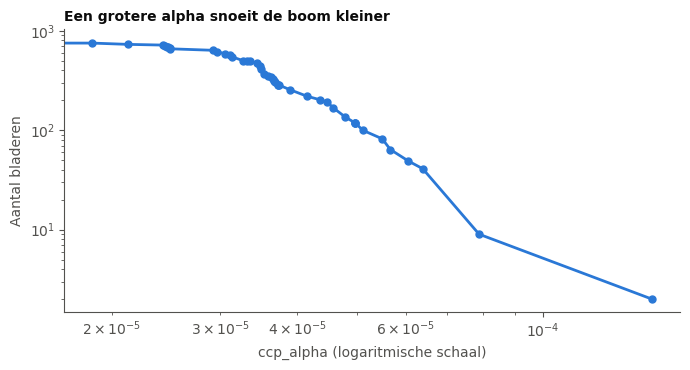

Bladeren van de volledige boom: 769 - diepte: 28


In [36]:
unpruned = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(
    X_train, y_train)
path = unpruned.cost_complexity_pruning_path(X_train, y_train)
alphas = path.ccp_alphas[:-1]  # de laatste alpha laat alleen de wortel over
leaves = [DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=a)
          .fit(X_train, y_train).get_n_leaves()
          for a in alphas[::max(1, len(alphas) // 40)]]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(alphas[::max(1, len(alphas) // 40)], leaves, color=BLUE,
        linewidth=2, marker="o", markersize=5)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("ccp_alpha (logaritmische schaal)")
ax.set_ylabel("Aantal bladeren")
ax.set_title("Een grotere alpha snoeit de boom kleiner", fontsize=10)
plt.tight_layout()
plt.show()
print("Bladeren van de volledige boom:", unpruned.get_n_leaves(),
      "- diepte:", unpruned.get_depth())

## 4.5 Tuning zonder techniek voor de scheve klassen

Een Decision Tree heeft geen standaardisatie nodig (paragraaf 1.8). De preprocessor staat toch in de pipeline, zodat de opzet gelijk is aan die van KNN. Dit verandert de uitkomst van de boom niet. Eerst worden de pre-pruning-parameters en het splitscriterium getuned.

In [37]:
dt_grid = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [3, 5, 8, 12, 20],
    "model__min_samples_leaf": [1, 20, 100, 300],
}
dt_columns = ["param_model__criterion", "param_model__max_depth",
              "param_model__min_samples_leaf"]

dt_plain = tune(
    make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    dt_grid, X_train, y_train, train_score=True)
print("Beste parameters:", dt_plain.best_params_)
print("Beste F1 (CV):", round(dt_plain.best_score_, 4))
top_results(dt_plain, dt_columns)

Beste parameters: {'model__criterion': 'entropy', 'model__max_depth': 20, 'model__min_samples_leaf': 1}
Beste F1 (CV): 0.0618


,param_model__criterion,param_model__max_depth,param_model__min_samples_leaf,F1_cv,std_cv
36,entropy,20,1,0.0618,0.0252
16,gini,20,1,0.0458,0.0186
12,gini,12,1,0.0394,0.0259
32,entropy,12,1,0.0304,0.0248
28,entropy,8,1,0.0199,0.0255


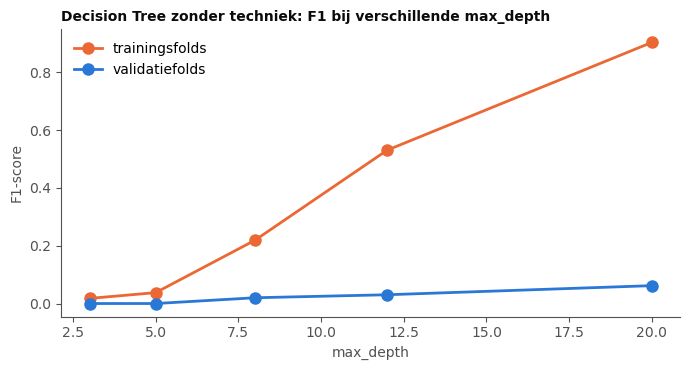

In [38]:
def plot_depth_curve(search, title):
    """Plot F1 op train en validatie tegen max_depth."""
    results = pd.DataFrame(search.cv_results_)
    best = search.best_params_
    mask = ((results["param_model__criterion"] == best["model__criterion"])
            & (results["param_model__min_samples_leaf"]
               == best["model__min_samples_leaf"]))
    subset = results[mask].sort_values("param_model__max_depth")
    depths = subset["param_model__max_depth"].astype(int)
    fig, ax = plt.subplots(figsize=(7, 3.8))
    ax.plot(depths, subset["mean_train_score"], color=ORANGE, linewidth=2,
            marker="o", markersize=8, label="trainingsfolds")
    ax.plot(depths, subset["mean_test_score"], color=BLUE, linewidth=2,
            marker="o", markersize=8, label="validatiefolds")
    ax.set_xlabel("max_depth")
    ax.set_ylabel("F1-score")
    ax.set_title(title, fontsize=10)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()


plot_depth_curve(dt_plain, "Decision Tree zonder techniek: F1 bij "
                 "verschillende max_depth")

## 4.6 Twee technieken voor de scheve klassenverdeling

**1. `class_weight="balanced"` (gewichten).** Elke patiënt krijgt een gewicht omgekeerd evenredig met de grootte van zijn klasse: $w_k = \frac{n}{2 \cdot n_k}$, met $n$ het aantal patiënten en $n_k$ het aantal in klasse $k$ (scikit-learn developers, n.d.-b). Een patiënt met een herseninfarct telt daardoor ongeveer 32 keer zo zwaar als een patiënt zonder. Er worden geen gegevens toegevoegd of weggegooid. Het nadeel is dat de boom gevoeliger wordt voor enkele patiënten met een herseninfarct, en dus makkelijker overfit.

**2. SMOTE (oversampling).** Zie paragraaf 3.6. Bij een boom wordt SMOTE toegepast op de trainingsfolds in de pipeline. Het nadeel van interpolatie tussen 0/1-kolommen geldt hier ook, al vergelijkt een boom met een drempel zodat een waarde als 0,4 gewoon bij 0 of 1 wordt ingedeeld.

In [39]:
dt_weight_grid = dict(dt_grid)
dt_smote_grid = dict(dt_grid)
dt_smote_grid["sampler__sampling_strategy"] = [0.1, 0.3, 1.0]

dt_weighted = tune(
    make_pipeline(DecisionTreeClassifier(class_weight="balanced",
                                         random_state=RANDOM_STATE)),
    dt_weight_grid, X_train, y_train)
dt_smote = tune(
    make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE),
                  SMOTE(random_state=RANDOM_STATE)),
    dt_smote_grid, X_train, y_train)

print("class_weight:", dt_weighted.best_params_)
print("SMOTE:", dt_smote.best_params_)
top_results(dt_weighted, dt_columns, n=3)

class_weight: {'model__criterion': 'entropy', 'model__max_depth': 5, 'model__min_samples_leaf': 20}
SMOTE: {'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 1, 'sampler__sampling_strategy': 0.3}


,param_model__criterion,param_model__max_depth,param_model__min_samples_leaf,F1_cv,std_cv
25,entropy,5,20,0.0901,0.0097
24,entropy,5,1,0.0900,0.0115
16,gini,20,1,0.0893,0.0208


In [40]:
top_results(dt_smote, dt_columns + ["param_sampler__sampling_strategy"],
            n=3)

,param_model__criterion,param_model__max_depth,param_model__min_samples_leaf,param_sampler__sampling_strategy,F1_cv,std_cv
1,gini,3,1,0.3,0.1272,0.0166
4,gini,3,20,0.3,0.1272,0.0166
7,gini,3,100,0.3,0.1272,0.0166


## 4.7 Post-pruning met `ccp_alpha`

De pre-pruning-parameters zijn getuned. Nu wordt voor elk van de drie modellen onderzocht of extra snoeien met `ccp_alpha` de F1 in de cross-validation nog verbetert. De andere parameters blijven op hun beste waarde staan. De alpha-waarden zijn een vast raster en zijn niet afgeleid van de data, omdat de schaal van alpha verschilt per model.

In [41]:
ALPHAS = [0, 1e-5, 1e-4, 5e-4, 1e-3, 3e-3]


def tune_alpha(search, sampler=None):
    """Probeer ccp_alpha op de beste parameters van een eerdere search."""
    estimator = clone(search.best_estimator_)
    grid = {"model__ccp_alpha": ALPHAS}
    return tune(estimator, grid, X_train, y_train)


dt_pruned = {
    "DT zonder techniek": tune_alpha(dt_plain),
    "DT + class_weight": tune_alpha(dt_weighted),
    "DT + SMOTE": tune_alpha(dt_smote),
}
pd.DataFrame({
    name: pd.Series(
        search.cv_results_["mean_test_score"], index=ALPHAS).round(4)
    for name, search in dt_pruned.items()}).rename_axis("ccp_alpha")

,DT zonder techniek,DT + class_weight,DT + SMOTE
ccp_alpha,,,
0.00000,0.0618,0.0901,0.1272
0.00001,0.0618,0.0901,0.1272
0.00010,0.0620,0.0901,0.1272
0.00050,0.0000,0.0901,0.1272
0.00100,0.0000,0.0901,0.1272
0.00300,0.0000,0.0895,0.1268


Post-pruning wordt alleen gebruikt als het de F1 in de cross-validation verhoogt. Houd er rekening mee dat de F1 per fold ongeveer 0,01 verschilt (zie `std_cv` hierboven): verschillen van 0,001 zijn dus ruis, en alleen een duidelijk hogere F1 is een echte verbetering.

In [42]:
dt_before = {
    "DT zonder techniek": dt_plain,
    "DT + class_weight": dt_weighted,
    "DT + SMOTE": dt_smote,
}
dt_models = {}
for name in dt_before:
    pruned = dt_pruned[name]
    use_pruned = pruned.best_score_ > dt_before[name].best_score_
    dt_models[name] = pruned if use_pruned else dt_before[name]
    print(f"{name}: F1 zonder extra snoeien "
          f"{dt_before[name].best_score_:.4f}, met alpha "
          f"{pruned.best_params_['model__ccp_alpha']}: "
          f"{pruned.best_score_:.4f} -> "
          f"{'met' if use_pruned else 'zonder'} post-pruning")

DT zonder techniek: F1 zonder extra snoeien 0.0618, met alpha 0.0001: 0.0620 -> met post-pruning
DT + class_weight: F1 zonder extra snoeien 0.0901, met alpha 0: 0.0901 -> zonder post-pruning
DT + SMOTE: F1 zonder extra snoeien 0.1272, met alpha 0: 0.1272 -> zonder post-pruning


## 4.8 Beoordeling van de Decision Tree

Net als bij KNN: de beste drempel wordt bepaald met cross-validation op `X_train`, en daarna worden de modellen beoordeeld op `X_val`.

In [43]:
dt_rows = {}
dt_thresholds = {}
for name, search in dt_models.items():
    threshold, f1_cv = cv_threshold(search.best_estimator_, X_train, y_train)
    dt_thresholds[name] = threshold
    on_val_default = evaluate(search.best_estimator_, X_val, y_val)
    on_val_tuned = evaluate(search.best_estimator_, X_val, y_val, threshold)
    dt_rows[name] = {
        "F1_cv_drempel_0.5": round(search.best_score_, 4),
        "F1_cv_beste_drempel": round(f1_cv, 4),
        "beste_drempel": round(threshold, 3),
        "F1_val_drempel_0.5": on_val_default["F1"],
        "F1_val_beste_drempel": on_val_tuned["F1"],
        "precision_val": on_val_tuned["precision"],
        "recall_val": on_val_tuned["recall"],
    }
pd.DataFrame(dt_rows).T

,F1_cv_drempel_0.5,F1_cv_beste_drempel,beste_drempel,F1_val_drempel_0.5,F1_val_beste_drempel,precision_val,recall_val
DT zonder techniek,0.0620,0.0936,0.081,0.0300,0.0783,0.0618,0.1068
DT + class_weight,0.0901,0.1471,0.841,0.0871,0.1091,0.0689,0.2621
DT + SMOTE,0.1272,0.1324,0.610,0.1077,0.1077,0.0647,0.3204


In [44]:
dt_choice = max(dt_rows, key=lambda name: dt_rows[name][
    "F1_cv_beste_drempel"])
print("Gekozen Decision Tree (hoogste F1 in CV):", dt_choice)
best_pipeline = dt_models[dt_choice].best_estimator_
model_params = best_pipeline.named_steps["model"].get_params()
print("Parameters:", {key: model_params[key] for key in [
    "criterion", "max_depth", "min_samples_leaf", "ccp_alpha",
    "class_weight"]})
print("Sampler:", dt_models[dt_choice].best_estimator_.named_steps.get(
    "sampler"))

chosen_tree = dt_models[dt_choice].best_estimator_.named_steps["model"]
feature_names = dt_models[dt_choice].best_estimator_.named_steps[
    "prep"].get_feature_names_out()
importances = pd.Series(chosen_tree.feature_importances_,
                        index=feature_names).sort_values(ascending=False)
importances.head(6).round(3).to_frame("belang")

Gekozen Decision Tree (hoogste F1 in CV): DT + class_weight
Parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 20, 'ccp_alpha': 0.0, 'class_weight': 'balanced'}
Sampler: None


,belang
age,0.827
avg_glucose_level,0.071
bmi,0.027
age_x_glucose,0.025
hypertension,0.015
age_x_hypertension,0.011


De wortel splitst op age <= 0.516 (gestandaardiseerd), dat is 53.5 jaar.


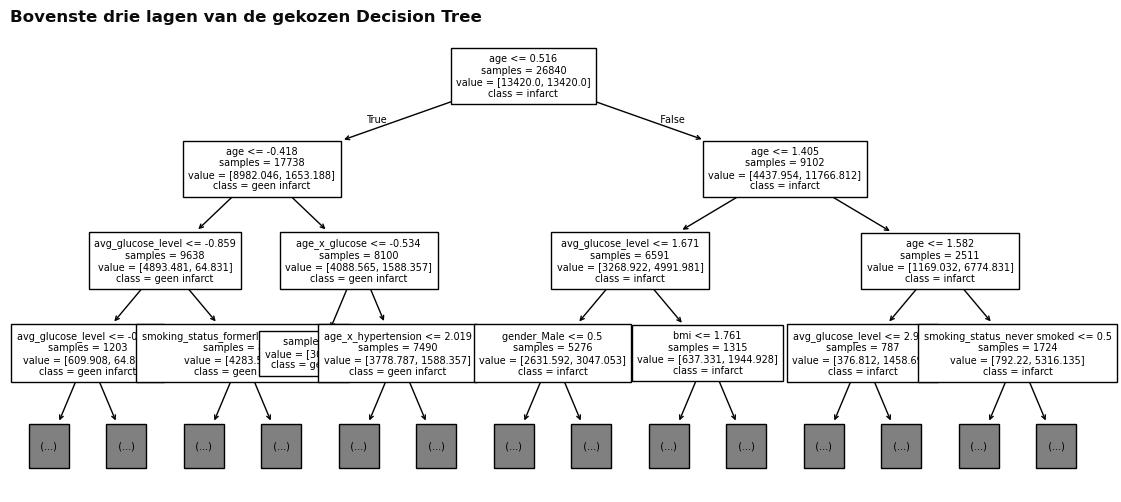

In [45]:
scaler = dt_models[dt_choice].best_estimator_.named_steps[
    "prep"].named_transformers_["scale"]
root_threshold = chosen_tree.tree_.threshold[0]
if feature_names[chosen_tree.tree_.feature[0]] == "age":
    age_mean, age_std = scaler.mean_[0], scaler.scale_[0]
    root_years = root_threshold * age_std + age_mean
    print(f"De wortel splitst op age <= {root_threshold:.3f} "
          f"(gestandaardiseerd), dat is {root_years:.1f} jaar.")

fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(chosen_tree, max_depth=3, feature_names=list(feature_names),
          class_names=["geen infarct", "infarct"], filled=False,
          fontsize=7, ax=ax, impurity=False, proportion=False)
ax.set_title("Bovenste drie lagen van de gekozen Decision Tree")
plt.show()

In de boom staan leeftijden in gestandaardiseerde eenheden, omdat de boom op de gestandaardiseerde data is getraind (zie de omrekening hierboven). De aantallen bij `samples` en `value` zijn die na SMOTE en niet de echte aantallen patiënten.

## 4.9 Kaggle-inzending voor de Decision Tree

In [46]:
dt_submission = make_submission(dt_models[dt_choice],
                                dt_thresholds[dt_choice],
                                "submission_dt.csv")
print("Aantal rijen:", len(dt_submission))
print("Voorspeld herseninfarct:", int(dt_submission["stroke"].sum()),
      f"({dt_submission['stroke'].mean():.2%}) - in train is dat "
      f"{y.mean():.2%}")
dt_submission.head()

Aantal rijen: 8388
Voorspeld herseninfarct: 540 (6.44%) - in train is dat 1.54%


,id,stroke
0,32840,0
1,45158,0
2,56105,0
3,3112,0
4,35224,0


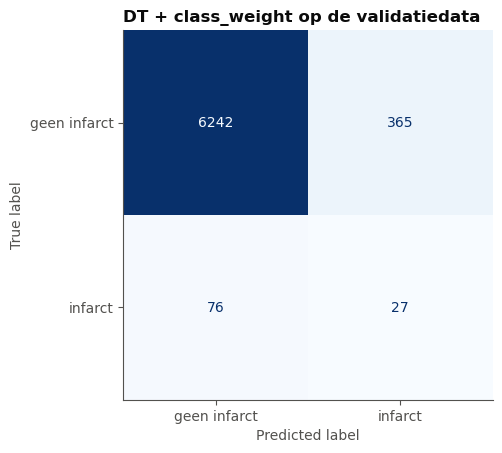

In [47]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    dt_models[dt_choice].best_estimator_.predict_proba(X_val)[:, 1]
    >= dt_thresholds[dt_choice],
    display_labels=["geen infarct", "infarct"], cmap="Blues",
    colorbar=False)
plt.title(f"{dt_choice} op de validatiedata")
plt.show()

# 5. Logistic Regression

Logistic Regression (LR) is een lineair classificatiemodel. In dit hoofdstuk wordt uitgelegd hoe het model werkt, welke loss-functie het minimaliseert, hoe gradient descent de gewichten aanpast, welke vormen van regularisatie bestaan en hoe deze de kans op overfitting beperken. Daarna wordt het model getuned met en zonder techniek voor de scheve klassenverdeling, en wordt het beste model op de validatieset uit paragraaf 1.9 beoordeeld. De pipeline, cross-validation en helperfuncties uit paragraaf 3.4 worden hergebruikt.

## 5.1 Hoe werkt Logistic Regression?

Voor elke patiënt met kenmerken $x = (x_1, x_2, \ldots, x_p)$ berekent LR eerst een lineaire combinatie:

$$z = w_0 + w_1 x_1 + w_2 x_2 + \ldots + w_p x_p$$

Hier zijn $w_1, \ldots, w_p$ de **gewichten** per kenmerk en is $w_0$ de **bias** (ook wel intercept). Omdat $z$ elke waarde van $-\infty$ tot $+\infty$ kan aannemen, wordt $z$ door de **sigmoïde functie** gestuurd om een kans tussen 0 en 1 te krijgen (James et al., 2021, p. 134):

$$\hat{p} = \sigma(z) = \frac{1}{1 + e^{-z}}$$

Een patiënt wordt voorspeld als 'infarct' zodra $\hat{p}$ boven een drempel ligt. De standaarddrempel is 0,5, maar in paragraaf 3.7 is al laten zien dat voor scheve data de beste drempel vaak lager ligt. Diezelfde drempeloptimalisatie wordt in paragraaf 5.9 ook hier toegepast.

## 5.2 De loss-functie: binary cross-entropy

LR leert de gewichten door een loss-functie te minimaliseren. Voor binaire classificatie is dat de **binary cross-entropy** of **log-loss** (scikit-learn developers, n.d.-k):

$$L(w) = -\frac{1}{n} \sum_{i=1}^{n} \Bigl[ y_i \log(\hat{p}_i) + (1 - y_i) \log(1 - \hat{p}_i) \Bigr]$$

Hierin is $n$ het aantal patiënten, $y_i \in \{0, 1\}$ het echte label en $\hat{p}_i = \sigma(w^\top x_i)$ de voorspelde kans. De functie straft het model zwaar als het met hoge zekerheid de verkeerde klasse voorspelt: $\log(0{,}01)$ is bijvoorbeeld $-4{,}6$, en dat getal vermenigvuldigt met het aantal patiënten geeft een grote som. Minimaliseren van $L$ betekent dus: zorg dat $\hat{p}_i$ dicht bij $y_i$ ligt voor élke patiënt.

## 5.3 Gradient descent met rekenvoorbeeld

Omdat $L(w)$ niet in één stap op te lossen is, worden de gewichten iteratief bijgewerkt met **gradient descent** (James et al., 2021, p. 403). De richting van de aanpassing is tegengesteld aan de gradiënt (de helling) van de loss:

$$w_{\text{nieuw}} = w_{\text{oud}} - \eta \cdot \frac{\partial L}{\partial w}$$

Hier is $\eta$ de **learning rate** (stapgrootte). Voor LR is de partiële afgeleide naar gewicht $w_j$:

$$\frac{\partial L}{\partial w_j} = \frac{1}{n} \sum_{i=1}^{n} (\hat{p}_i - y_i) \cdot x_{ij}$$

De term $(\hat{p}_i - y_i)$ is simpel: de voorspelde kans min de echte uitkomst (het *residu*). Grote residuen trekken het gewicht harder.

In de cel hieronder wordt één gradient descent-stap met de hand uitgerekend op twee bedachte patiënten met één kenmerk (bijvoorbeeld een gestandaardiseerde leeftijd). Hiermee is te volgen welke getallen in welke formule worden ingevuld.

In [48]:
# Eén stap gradient descent op twee bedachte patiënten (rekenvoorbeeld).
# Patient A: x = 1 (oudere patient, gestandaardiseerd), y = 1 (infarct)
# Patient B: x = -1 (jongere patient, gestandaardiseerd), y = 0 (geen infarct)

def sigmoid(z):
    # Sigmoide functie uit paragraaf 5.1.
    return 1 / (1 + np.exp(-z))


x_demo = np.array([1.0, -1.0])
y_demo = np.array([1, 0])

w, b = 0.0, 0.0       # startgewichten
eta = 0.5             # learning rate

z = w * x_demo + b
p_hat = sigmoid(z)
residu = p_hat - y_demo
grad_w = np.mean(residu * x_demo)
grad_b = np.mean(residu)

w_nieuw = w - eta * grad_w
b_nieuw = b - eta * grad_b

print(f"z         = {z}")
print(f"p_hat     = {p_hat}")
print(f"residu    = {residu}")
print(f"grad_w    = {grad_w:.4f}")
print(f"grad_b    = {grad_b:.4f}")
print(f"nieuwe w  = {w_nieuw:.4f}")
print(f"nieuwe b  = {b_nieuw:.4f}")


z         = [0. 0.]
p_hat     = [0.5 0.5]
residu    = [-0.5  0.5]
grad_w    = -0.5000
grad_b    = 0.0000
nieuwe w  = 0.2500
nieuwe b  = 0.0000


Na één stap is $w$ positief geworden: oudere patiënten krijgen daarmee een hogere kans op 'infarct', wat klopt met de EDA (paragraaf 1.5). In de praktijk herhaalt scikit-learn deze stap duizenden keren tot $L(w)$ bijna niet meer daalt. Dat gebeurt automatisch door de `solver` (bijvoorbeeld `lbfgs` of `saga`). De parameter `max_iter` beperkt het aantal iteraties.

## 5.4 Regularisatie en overfitting

Zonder beperking kunnen de gewichten $w_j$ heel groot worden om de trainingsdata exact te volgen. Een scherp bochtig beslisgebied past dan goed op de train maar slecht op nieuwe data: **overfitting** (Hastie et al., 2009, p. 61). Regularisatie voegt een strafterm toe aan de loss, zodat grote gewichten "duur" worden en het model zijn beslisgebied zachter maakt.

**L2-regularisatie (ridge).** Straf op de kwadraten van de gewichten:

$$L_{\text{L2}}(w) = L(w) + \lambda \sum_{j=1}^{p} w_j^2$$

Alle gewichten worden naar 0 getrokken, maar bijna nooit precies 0. Resultaat: een vlakker model dat alle kenmerken blijft gebruiken.

**L1-regularisatie (lasso).** Straf op de absolute waarden:

$$L_{\text{L1}}(w) = L(w) + \lambda \sum_{j=1}^{p} |w_j|$$

L1 duwt sommige gewichten exact naar 0 en doet daarmee *feature selection*: kenmerken die niet nodig zijn, verdwijnen uit het model.

**Elastic net.** Een combinatie van beide:

$$L_{\text{EN}}(w) = L(w) + \lambda \Bigl( \alpha \sum_j |w_j| + (1-\alpha) \sum_j w_j^2 \Bigr)$$

Met $\alpha \in [0, 1]$ wordt de mix bepaald ($\alpha = 1$ is pure L1, $\alpha = 0$ is pure L2).

**Relatie met overfitting.** Een hogere $\lambda$ (sterker straf) houdt gewichten kleiner, dus simpeler model, minder overfitting, maar bij overdrijving: underfitting. In scikit-learn werkt niet $\lambda$ maar `C = 1 / λ`: *hoge* `C` betekent *weinig* regularisatie, *lage* `C` betekent *veel* regularisatie (scikit-learn developers, n.d.-l).

## 5.5 Hyperparameters van Logistic Regression

| Hyperparameter | Betekenis | Effect |
|---|---|---|
| `C` | $1/\lambda$ (sterkte van regularisatie, omgekeerd) | Lage `C`: veel straf, kleine gewichten, risico op underfitting. Hoge `C`: weinig straf, risico op overfitting. |
| `penalty` | `'l1'`, `'l2'`, `'elasticnet'` of `'none'` | Keuze van strafterm (zie paragraaf 5.4). |
| `solver` | Optimalisatie-algoritme | `'liblinear'` ondersteunt L1/L2; `'saga'` ondersteunt alle penalties en schaalt goed; `'lbfgs'` alleen L2/none. |
| `l1_ratio` | $\alpha$ voor elastic net | Alleen van toepassing bij `penalty='elasticnet'`. |
| `max_iter` | Maximaal aantal iteraties | Groot genoeg kiezen zodat de solver convergeert (anders waarschuwing). |
| `class_weight` | `None` of `'balanced'` | Zie paragraaf 5.7. |

## 5.6 Tuning zonder techniek voor de scheve klassen

Eerst wordt LR afgesteld zonder techniek voor de scheve klassenverdeling. Dit vormt de vergelijkingsbasis voor paragraaf 5.7. De `solver='saga'` ondersteunt zowel L1 als L2, en gebruikt de gestandaardiseerde features uit de pipeline. `GridSearchCV` zoekt met 5-voudige gestratificeerde cross-validation naar de hoogste F1-score.

In [49]:
# Importeren LR en toe voegen aan de pipeline uit paragraaf 3.4.

LR_BASE = LogisticRegression(solver="liblinear", max_iter=2000,
                             random_state=RANDOM_STATE)

lr_grid = {
    "model__C": [0.01, 0.1, 1.0, 10.0],
    "model__penalty": ["l1", "l2"],
}
lr_columns = ["param_model__C", "param_model__penalty"]

lr_plain = tune(make_pipeline(LR_BASE), lr_grid, X_train, y_train)
print("Beste parameters:", lr_plain.best_params_)
print("F1_cv:", round(lr_plain.best_score_, 4))

Beste parameters: {'model__C': 0.01, 'model__penalty': 'l1'}
F1_cv: 0.0


In [50]:
top_results(lr_plain, lr_columns, n=5)

,param_model__C,param_model__penalty,F1_cv,std_cv
0,0.01,l1,0.0,0.0
1,0.01,l2,0.0,0.0
2,0.10,l1,0.0,0.0
3,0.10,l2,0.0,0.0
4,1.00,l1,0.0,0.0


## 5.7 Twee technieken voor de scheve klassenverdeling

Zonder correctie voorspelt een lineair model vrijwel altijd de meerderheidsklasse (zie ook paragraaf 2.5). Twee technieken:

**1. `class_weight='balanced'` (gewichten).** De loss krijgt per klasse een gewicht $w_k = \frac{n}{2 \cdot n_k}$ (scikit-learn developers, n.d.-m). De 1,54% positieve patiënten tellen daardoor ongeveer 32× zwaarder, zodat ze de gewichten net zo hard trekken als de meerderheidsklasse.

**2. SMOTE (oversampling).** Zoals in paragraaf 3.6 bij KNN: synthetische positieve patiënten tussen echte buren erbij maken (Chawla et al., 2002). SMOTE zit vóór het model in de pipeline, zodat het alleen op de trainingsfolds wordt toegepast en niet op de validatiefolds.

In [51]:
# LR met class_weight='balanced'.
LR_WEIGHTED = LogisticRegression(solver="liblinear", max_iter=2000,
                                 class_weight="balanced",
                                 random_state=RANDOM_STATE)

lr_weighted = tune(make_pipeline(LR_WEIGHTED), lr_grid, X_train, y_train)
print("Beste parameters:", lr_weighted.best_params_)
print("F1_cv:", round(lr_weighted.best_score_, 4))


Beste parameters: {'model__C': 0.01, 'model__penalty': 'l2'}
F1_cv: 0.0921


In [52]:
# LR met SMOTE voor de minderheidsklasse.
lr_smote_grid = dict(lr_grid)
lr_smote_grid["sampler__sampling_strategy"] = [0.1, 0.3, 1.0]

lr_smote = tune(
    make_pipeline(LR_BASE, SMOTE(random_state=RANDOM_STATE)),
    lr_smote_grid, X_train, y_train)
print("Beste parameters:", lr_smote.best_params_)
print("F1_cv:", round(lr_smote.best_score_, 4))


Beste parameters: {'model__C': 0.01, 'model__penalty': 'l2', 'sampler__sampling_strategy': 0.3}
F1_cv: 0.1438


## 5.8 Beoordeling op de validatieset

Net als bij KNN en de Decision Tree: eerst wordt per variant de beste drempel bepaald met cross-validation op `X_train`, daarna worden alle drie de modellen beoordeeld op `X_val`. Zo ziet de validatieset geen enkel stuk van het tunen. De getallen in de tabel komen uit cross-validation (`F1_cv_...`) en uit de validatieset (`F1_val_...`); dat verschil wordt expliciet aangegeven.

In [53]:
lr_models = {
    "LR zonder techniek": lr_plain,
    "LR + class_weight": lr_weighted,
    "LR + SMOTE": lr_smote,
}

lr_rows = {}
lr_thresholds = {}
for name, search in lr_models.items():
    threshold, f1_cv = cv_threshold(search.best_estimator_, X_train, y_train)
    lr_thresholds[name] = threshold
    on_val_default = evaluate(search.best_estimator_, X_val, y_val)
    on_val_tuned = evaluate(search.best_estimator_, X_val, y_val, threshold)
    lr_rows[name] = {
        "F1_cv_drempel_0.5": round(search.best_score_, 4),
        "F1_cv_beste_drempel": round(f1_cv, 4),
        "beste_drempel": round(threshold, 3),
        "F1_val_drempel_0.5": on_val_default["F1"],
        "F1_val_beste_drempel": on_val_tuned["F1"],
        "precision_val": on_val_tuned["precision"],
        "recall_val": on_val_tuned["recall"],
    }
pd.DataFrame(lr_rows).T


,F1_cv_drempel_0.5,F1_cv_beste_drempel,beste_drempel,F1_val_drempel_0.5,F1_val_beste_drempel,precision_val,recall_val
LR zonder techniek,0.0000,0.1509,0.067,0.0000,0.1127,0.0884,0.1553
LR + class_weight,0.0921,0.1534,0.851,0.0907,0.1021,0.0739,0.1650
LR + SMOTE,0.1438,0.1485,0.567,0.1102,0.1035,0.0683,0.2136


## 5.9 Kaggle-inzending voor Logistic Regression

Het model met de hoogste F1 in de cross-validation wordt opnieuw gefit op de volledige `train.csv` (trainings- en validatiedeel samen) en toegepast op `test.csv`. Het bestand `submission_lr.csv` wordt op Kaggle geüpload. De confusion matrix op de validatieset dient als visuele controle.

Gekozen LR-model (hoogste F1 in CV): LR + class_weight
Aantal rijen: 8388
Voorspeld herseninfarct: 329 (3.92%) - in train is dat 1.54%


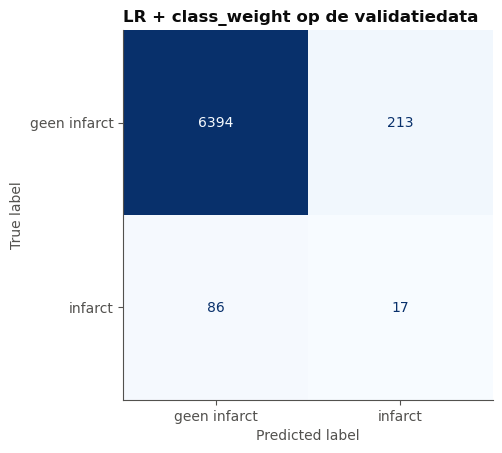

In [54]:
lr_choice = max(lr_rows, key=lambda name: lr_rows[name][
    "F1_cv_beste_drempel"])
print("Gekozen LR-model (hoogste F1 in CV):", lr_choice)
lr_submission = make_submission(lr_models[lr_choice],
                                lr_thresholds[lr_choice],
                                "submission_lr.csv")
print("Aantal rijen:", len(lr_submission))
print("Voorspeld herseninfarct:", int(lr_submission["stroke"].sum()),
      f"({lr_submission['stroke'].mean():.2%}) - in train is dat "
      f"{y.mean():.2%}")

ConfusionMatrixDisplay.from_predictions(
    y_val,
    lr_models[lr_choice].best_estimator_.predict_proba(X_val)[:, 1]
    >= lr_thresholds[lr_choice],
    display_labels=["geen infarct", "infarct"], cmap="Blues",
    colorbar=False)
plt.title(f"{lr_choice} op de validatiedata")
plt.show()


# 6. Support Vector Machine (SVM)

Een Support Vector Machine zoekt het **beslisvlak** (de *hyperplane*) dat de twee klassen zo ver mogelijk uit elkaar legt. In dit hoofdstuk komen aan bod: hoe het model werkt, een handberekening op een klein voorbeeld, de kernel en de kernel trick, de hinge-loss, de vormen van regularisatie, en de tuning op de stroke-dataset. Omdat een klassieke SVM met een niet-lineaire kernel op 26.000 patiënten erg traag is, wordt voor de tuning de snellere `LinearSVC` gebruikt, verpakt in `CalibratedClassifierCV` zodat `predict_proba` beschikbaar is voor de drempeloptimalisatie uit paragraaf 3.4.

## 6.1 Hoe werkt SVM?

Een lineaire SVM representeert het beslisvlak als:

$$f(x) = w^\top x + b = 0$$

Een patiënt met $f(x) > 0$ wordt geclassificeerd als klasse $+1$, met $f(x) < 0$ als klasse $-1$. SVM kiest $w$ en $b$ zó, dat de **marge** (de afstand van het beslisvlak tot het dichtstbijzijnde punt per klasse) zo groot mogelijk is. De marge is $\frac{2}{\|w\|}$, dus marge maximaliseren is gelijk aan $\|w\|$ minimaliseren (James et al., 2021, p. 371).

Voor data die niet perfect scheidbaar is, wordt een **slack** $\xi_i \geq 0$ per patiënt toegestaan die aangeeft hoeveel die patiënt binnen de marge of aan de verkeerde kant mag liggen. Dat heet een **soft-margin SVM**:

$$\min_{w, b, \xi} \; \tfrac{1}{2} \|w\|^2 + C \sum_{i=1}^{n} \xi_i
\quad \text{onder voorwaarde} \quad
y_i (w^\top x_i + b) \geq 1 - \xi_i, \; \xi_i \geq 0$$

De parameter $C$ regelt hoeveel foute of grens-patiënten worden "gestraft" (zie paragraaf 6.4). De patiënten met $\xi_i > 0$ of die precies op de marge liggen, heten **support vectors**: alleen zij bepalen het beslisvlak.

### Rekenvoorbeeld op drie punten

Om de getallen tastbaar te maken, hieronder een rekenvoorbeeld met drie bedachte patiënten in twee dimensies. Dit voorbeeld is bewust klein (3 patiënten, 2 kenmerken) zodat elke berekening met de hand te volgen is. Voor de echte dataset gaat scikit-learn dit optimalisatieprobleem oplossen voor alle $n = 26\,840$ trainingspatiënten in de 18-dimensionale ruimte.

In [55]:
# Drie bedachte patiënten met 2 kenmerken (bv. gestandaardiseerde age en bmi).
# Klasse +1 = infarct, klasse -1 = geen infarct.
x_svm = np.array([[1.0, 1.0],   # patient A, infarct
                  [2.0, 2.0],   # patient B, infarct
                  [0.0, 0.0]])  # patient C, geen infarct
y_svm = np.array([+1, +1, -1])

# Kies een geldig beslisvlak: w = (1, 1), b = -1.5
w_svm = np.array([1.0, 1.0])
b_svm = -1.5

f_values = x_svm @ w_svm + b_svm
margin = 2 / np.linalg.norm(w_svm)
print("f(x) per patient:", f_values)
print("Teken y * f(x)  :", y_svm * f_values, "(moet overal >= 0)")
print(f"||w||          : {np.linalg.norm(w_svm):.4f}")
print(f"marge          : {margin:.4f}")


f(x) per patient: [ 0.5  2.5 -1.5]
Teken y * f(x)  : [0.5 2.5 1.5] (moet overal >= 0)
||w||          : 1.4142
marge          : 1.4142


De uitvoer bevestigt: alle $y_i \cdot f(x_i) \geq 0$, dus de drie patiënten worden correct geclassificeerd. De marge is $\frac{2}{\sqrt{2}} \approx 1{,}41$. Als een echte SVM dit optimum zoekt, probeert hij een nog grotere marge te vinden door $w$ aan te passen. Scikit-learn doet dit met een kwadratisch programmeringsalgoritme (`SVC`) of een coordinate descent-variant (`LinearSVC`).

## 6.2 Kernels en de kernel trick

Veel echte problemen zijn niet lineair scheidbaar. SVM lost dit op door de patiënten eerst door een afbeelding $\phi$ naar een hogere dimensie te sturen, waar ze wel lineair te scheiden zijn (James et al., 2021, p. 379). In plaats van $\phi(x)$ expliciet te berekenen (vaak duur of oneindig-dimensioneel), rekent SVM alleen met **inproducten** $\phi(x_i)^\top \phi(x_j)$. Een **kernel** $K$ geeft dat inproduct rechtstreeks terug:

$$K(x_i, x_j) = \phi(x_i)^\top \phi(x_j)$$

Dit heet de **kernel trick**: het algoritme werkt in de hogere dimensie zonder er ooit naartoe te hoeven rekenen. Veelgebruikte kernels (scikit-learn developers, n.d.-n):

| Kernel | Formule | Wanneer |
|---|---|---|
| Lineair | $K(x_i, x_j) = x_i^\top x_j$ | Als een rechte scheiding genoeg is; snelst (`LinearSVC`). |
| Polynomiaal | $K(x_i, x_j) = (x_i^\top x_j + c)^d$ | Voor krommingen van graad $d$. |
| RBF (Gaussian) | $K(x_i, x_j) = \exp(-\gamma \|x_i - x_j\|^2)$ | Flexibel, standaardkeuze voor niet-lineaire problemen. |

Voor de stroke-dataset is in paragraaf 1.5 gezien dat de kenmerken grotendeels monotoon samenhangen met stroke. Daarom wordt hieronder een lineaire SVM getuned; een RBF-kernel zou kunnen worden geprobeerd ten koste van veel rekentijd (`SVC(kernel='rbf')`).

## 6.3 De loss-functie: hinge loss

Voor één patiënt is de **hinge loss**:

$$L_i(w, b) = \max\Bigl(0,\; 1 - y_i \bigl(w^\top x_i + b\bigr)\Bigr)$$

De term binnen $\max$ is 0 als de patiënt met voldoende marge aan de goede kant van het beslisvlak ligt ($y_i f(x_i) \geq 1$); anders is er lineaire straf. Grafisch is dit de "scharnier" (hinge) die ingaat op het punt $y_i f(x_i) = 1$ (James et al., 2021, p. 367). De totale loss bij een lineaire SVM met L2-regularisatie:

$$L(w, b) = \frac{1}{n} \sum_{i=1}^{n} \max\bigl(0, 1 - y_i (w^\top x_i + b)\bigr) + \lambda \|w\|^2$$

Dit is equivalent aan de soft-margin formulering uit paragraaf 6.1, met $C = \frac{1}{2 n \lambda}$. In `LinearSVC` wordt standaard `loss='squared_hinge'` gebruikt (het kwadraat ervan) omdat dat sneller optimaliseert; `loss='hinge'` geeft de hierboven getoonde klassieke vorm.

## 6.4 Regularisatie bij SVM

**L2-regularisatie (standaard).** De term $\lambda \|w\|^2$ (of $\tfrac{1}{2}\|w\|^2$ in de soft-margin vorm) houdt $\|w\|$ klein. Een kleinere $\|w\|$ betekent een grotere marge en een gladder beslisvlak dus minder overfitting. In scikit-learn werkt niet $\lambda$ maar `C`: lagere `C` = meer regularisatie = grotere marge, hogere `C` = minder regularisatie = model past zich sterker aan elke patiënt aan (scikit-learn developers, n.d.-o).

**L1-regularisatie.** Alleen beschikbaar via `LinearSVC(penalty='l1', dual=False, loss='squared_hinge')`. Zoals bij LR duwt L1 sommige gewichten exact naar 0, wat kan helpen om onbelangrijke kenmerken weg te laten.

**Relatie met overfitting.** Net als bij LR: te hoge `C` ⇒ gewichten groeien, marge krimpt, overfitting; te lage `C` ⇒ marge wordt dominant maar classificatie wordt slordig (underfitting). De juiste `C` wordt gevonden met cross-validation.

## 6.5 Hyperparameters van (Linear)SVC

| Hyperparameter | Betekenis | Effect |
|---|---|---|
| `C` | $1/\lambda$ | Lage `C`: brede marge, veel regularisatie, mogelijk underfit. Hoge `C`: krappe marge, past zich aan patiënten aan, mogelijk overfit. |
| `kernel` (SVC) | `'linear'`, `'poly'`, `'rbf'`, `'sigmoid'` | Keuze van kernel (paragraaf 6.2). |
| `gamma` (SVC) | Kernelparameter voor `rbf`/`poly`/`sigmoid` | Lage gamma: brede invloed per punt (vlak); hoge gamma: smalle invloed (bochtig). |
| `degree` (SVC) | Graad voor `poly` | Hogere graad: krommere grens. |
| `penalty` (LinearSVC) | `'l1'` of `'l2'` | Zie paragraaf 6.4. |
| `loss` (LinearSVC) | `'hinge'` of `'squared_hinge'` | Zie paragraaf 6.3. |
| `class_weight` | `None` of `'balanced'` | Zie paragraaf 6.7. |

## 6.6 Tuning zonder techniek voor de scheve klassen

`LinearSVC` wordt in `CalibratedClassifierCV` verpakt (`method='sigmoid'`, Platt scaling, Platt, 1999). Dat voegt een `predict_proba` toe, zodat `cv_threshold` en `evaluate` uit paragraaf 3.4 ongewijzigd kunnen worden gebruikt. Het grid is bewust klein gehouden om de rekentijd beperkt te houden; `max_iter=5000` voorkomt convergentiewaarschuwingen.

In [56]:
def svm_base(class_weight=None):
    # Linear SVM met Platt scaling voor predict_proba.
    base = LinearSVC(penalty="l2", loss="squared_hinge", dual=False,
                     max_iter=5000, class_weight=class_weight,
                     random_state=RANDOM_STATE)
    return CalibratedClassifierCV(estimator=base, method="sigmoid", cv=3)


svm_grid = {"model__estimator__C": [0.01, 0.1, 1.0, 10.0]}
svm_columns = ["param_model__estimator__C"]

svm_plain = tune(make_pipeline(svm_base()), svm_grid, X_train, y_train)
print("Beste parameters:", svm_plain.best_params_)
print("F1_cv:", round(svm_plain.best_score_, 4))


Beste parameters: {'model__estimator__C': 0.01}
F1_cv: 0.0095


In [57]:
top_results(svm_plain, svm_columns, n=4)

,param_model__estimator__C,F1_cv,std_cv
0,0.01,0.0095,0.0116
2,1.00,0.0048,0.0095
3,10.00,0.0048,0.0095
1,0.10,0.0047,0.0094


## 6.7 Twee technieken voor de scheve klassenverdeling

Dezelfde twee technieken als bij KNN en LR:

**1. `class_weight='balanced'`.** Elke patiënt krijgt gewicht $w_k = \frac{n}{2 n_k}$ in de hinge loss. Hierdoor tellen fouten op de kleine klasse ongeveer 32× zo zwaar als die op de meerderheid.

**2. SMOTE.** Zoals in paragraaf 3.6: synthetische positieve patiënten tussen echte buren erbij maken, alleen op de trainingsfolds.

**Waarom `class_weight` bij drempel 0,5 een F1 van 0 kan geven.** `GridSearchCV` meet F1 met de standaarddrempel 0,5. `LinearSVC` wordt verpakt in `CalibratedClassifierCV`, die ruwe `decision_function`-waarden omzet in kansen via Platt-scaling. Bij sterke regularisatie (bijvoorbeeld `C=0.01`) blijven die kansen rond het base-rate (1,54%) hangen, dus onder 0,5: `predict()` geeft dan 0 positieve voorspellingen en F1 = 0. Dat betekent niet dat het model niets heeft geleerd, alleen dat de drempel niet geschikt is. In paragraaf 6.8 wordt de drempel per variant geoptimaliseerd met `cv_threshold`, en pas dan is te zien wat `class_weight` echt kan. SMOTE heeft dit probleem niet omdat de trainingsfolds daar bijna 30/70 verdeeld zijn, waardoor de calibratie wél kansen boven 0,5 produceert.

In [58]:
# SVM met class_weight='balanced'.
svm_weighted = tune(make_pipeline(svm_base(class_weight="balanced")),
                    svm_grid, X_train, y_train)
print("Beste parameters:", svm_weighted.best_params_)
print("F1_cv:", round(svm_weighted.best_score_, 4))


Beste parameters: {'model__estimator__C': 0.01}
F1_cv: 0.0


In [59]:
# SVM met SMOTE.
svm_smote_grid = dict(svm_grid)
svm_smote_grid["sampler__sampling_strategy"] = [0.1, 0.3, 1.0]

svm_smote = tune(
    make_pipeline(svm_base(), SMOTE(random_state=RANDOM_STATE)),
    svm_smote_grid, X_train, y_train)
print("Beste parameters:", svm_smote.best_params_)
print("F1_cv:", round(svm_smote.best_score_, 4))


Beste parameters: {'model__estimator__C': 0.01, 'sampler__sampling_strategy': 0.3}
F1_cv: 0.1369


## 6.8 Beoordeling op de validatieset

Zelfde opzet als bij KNN, Decision Tree en LR: beste drempel bepaald met cross-validation op `X_train`, daarna metrics berekend op `X_val`. In de kolomnamen is `F1_cv_...` uit cross-validation en `F1_val_...` uit de validatieset.

In [60]:
svm_models = {
    "SVM zonder techniek": svm_plain,
    "SVM + class_weight": svm_weighted,
    "SVM + SMOTE": svm_smote,
}

svm_rows = {}
svm_thresholds = {}
for name, search in svm_models.items():
    threshold, f1_cv = cv_threshold(search.best_estimator_, X_train, y_train)
    svm_thresholds[name] = threshold
    on_val_default = evaluate(search.best_estimator_, X_val, y_val)
    on_val_tuned = evaluate(search.best_estimator_, X_val, y_val, threshold)
    svm_rows[name] = {
        "F1_cv_drempel_0.5": round(search.best_score_, 4),
        "F1_cv_beste_drempel": round(f1_cv, 4),
        "beste_drempel": round(threshold, 3),
        "F1_val_drempel_0.5": on_val_default["F1"],
        "F1_val_beste_drempel": on_val_tuned["F1"],
        "precision_val": on_val_tuned["precision"],
        "recall_val": on_val_tuned["recall"],
    }
pd.DataFrame(svm_rows).T


,F1_cv_drempel_0.5,F1_cv_beste_drempel,beste_drempel,F1_val_drempel_0.5,F1_val_beste_drempel,precision_val,recall_val
SVM zonder techniek,0.0095,0.1545,0.058,0.0000,0.1240,0.0858,0.2233
SVM + class_weight,0.0000,0.1547,0.063,0.0000,0.1261,0.0804,0.2913
SVM + SMOTE,0.1369,0.1408,0.521,0.1107,0.1040,0.0633,0.2913


## 6.9 Kaggle-inzending voor SVM

Het SVM-model met de hoogste F1 in de cross-validation wordt opnieuw gefit op de volledige `train.csv` en toegepast op `test.csv`. Het bestand `submission_svm.csv` wordt op Kaggle geüpload. De confusion matrix op de validatieset dient als visuele controle.

Gekozen SVM-model (hoogste F1 in CV): SVM + class_weight
Aantal rijen: 8388
Voorspeld herseninfarct: 511 (6.09%) - in train is dat 1.54%


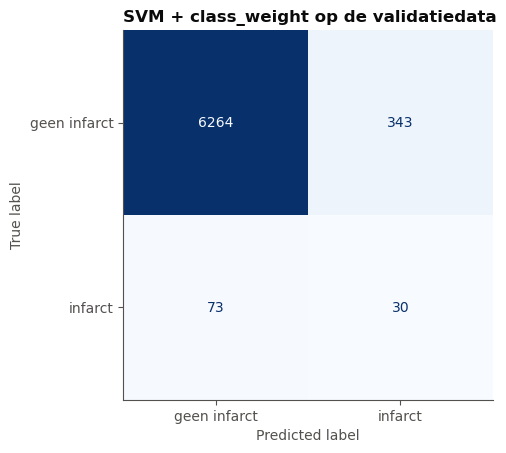

In [61]:
svm_choice = max(svm_rows, key=lambda name: svm_rows[name][
    "F1_cv_beste_drempel"])
print("Gekozen SVM-model (hoogste F1 in CV):", svm_choice)
svm_submission = make_submission(svm_models[svm_choice],
                                 svm_thresholds[svm_choice],
                                 "submission_svm.csv")
print("Aantal rijen:", len(svm_submission))
print("Voorspeld herseninfarct:", int(svm_submission["stroke"].sum()),
      f"({svm_submission['stroke'].mean():.2%}) - in train is dat "
      f"{y.mean():.2%}")

ConfusionMatrixDisplay.from_predictions(
    y_val,
    svm_models[svm_choice].best_estimator_.predict_proba(X_val)[:, 1]
    >= svm_thresholds[svm_choice],
    display_labels=["geen infarct", "infarct"], cmap="Blues",
    colorbar=False)
plt.title(f"{svm_choice} op de validatiedata")
plt.show()


# 7. Ensembles: Random Forest, Gradient Boosting en XGBoost

Een *ensemble* combineert veel eenvoudige modellen (hier beslisbomen) tot één sterker model. Dit hoofdstuk werkt het onderdeel 'Ensembles' van Opdracht 3 uit. De opzet is dezelfde als bij KNN, de Decision Tree, LR en SVM (paragraaf 3.4): één `Pipeline`, `GridSearchCV` met F1 en gestratificeerde 5-voudige cross-validation op `X_train`, een beste drempel uit cross-validation en een eenmalige beoordeling op `X_val`. De helperfuncties `make_pipeline`, `tune`, `cv_threshold`, `evaluate` en `make_submission` uit hoofdstuk 3 worden hergebruikt.

## 7.1 Waarom is deze dataset imbalanced?

Slechts 1,54% van de patiënten heeft een herseninfarct (paragraaf 1.3). Een herseninfarct is een zeldzame gebeurtenis: de meeste patiënten in de data zijn jong (mediane leeftijd 43 jaar), en alleen onder oudere patiënten met hartziekte, hypertensie of een hoog glucosegehalte komt een infarct vaker voor (paragraaf 1.6). De scheefheid komt dus voort uit het verschijnsel zelf en is niet het gevolg van een fout in de data. Een model dat de accuracy maximaliseert, kan 98,46% halen door iedereen als 'geen infarct' te voorspellen (paragraaf 2.5). In de zorg is dat onbruikbaar, omdat een gemiste patiënt (false negative) ernstige gevolgen kan hebben. Daarom wordt F1 gebruikt, en worden per ensemble minstens twee technieken tegen de scheve verdeling toegepast.

## 7.2 Bagging en boosting

**Bagging (bootstrap aggregation).** Er worden $B$ bomen getraind, elk op een *bootstrap-steekproef*: een willekeurige trekking met teruglegging van $n$ patiënten uit de trainingsdata. Elke boom ziet daardoor een iets andere dataset. De bomen zijn onafhankelijk van elkaar en worden dus **parallel** getraind. De voorspelling is de meerderheid van de bomen (of het gemiddelde van hun kansen). Middelen over veel bomen verlaagt de variantie en dus de kans op overfitting (Breiman, 2001).

**Random Forest** is bagging met een extra stap: bij elke splitsing mag een boom maar uit een willekeurige deelverzameling van de kenmerken kiezen (`max_features`). Zo lijken de bomen minder op elkaar, en wordt het gemiddelde beter (Breiman, 2001).

**Boosting.** De bomen worden **sequentieel** (na elkaar) getraind. Elke nieuwe, ondiepe boom leert de fouten (residuen) van het model tot dan toe te corrigeren. De voorspelling is de som van alle bomen, elk met een gewicht van `learning_rate`:

$$F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x)$$

Hierin is $h_m$ de nieuwe boom en $\eta$ de learning rate (Friedman, 2001). Boosting verlaagt vooral de bias, maar kan bij te veel bomen overfitten.

**Gradient Boosting (GBDT)** doet dit met de gradiënt van de loss: elke nieuwe boom wordt gefit op de negatieve gradiënt van de loss bij het huidige model (Friedman, 2001). **XGBoost** is een snelle implementatie hiervan met extra regularisatie op de bladgewichten (`reg_lambda`, `reg_alpha`), een tweede-orde benadering van de loss en parallelle berekening van de splitsingen binnen één boom (Chen & Guestrin, 2016).

**Trainingstijd.** Random Forest heeft weinig tijd nodig, omdat de bomen parallel kunnen worden getraind. Gradient Boosting en XGBoost zijn per definitie sequentieel: boom $m$ heeft boom $m-1$ nodig. De Gradient Boosting van Scikit-learn is hierdoor het traagst. XGBoost is sneller, doordat de splitsingen binnen één boom wel parallel worden berekend. De gemeten tijden staan in paragraaf 7.7.

## 7.3 Twee technieken voor de scheve klassenverdeling

Per ensemble worden drie varianten getuned: zonder techniek, en met twee technieken.

**1. SMOTE (oversampling).** Zoals in paragraaf 3.6: synthetische patiënten met een infarct worden gemaakt op de lijn tussen een echte patiënt en een van zijn buren uit dezelfde klasse (Chawla et al., 2002). SMOTE zit in de `Pipeline` en wordt dus alleen op de trainingsfolds toegepast. Zo kan een gesimuleerde patiënt nooit in de validatiefold terechtkomen (data leakage).

**2. Een kostengevoelige techniek, per model verschillend.**

- *Random Forest:* `class_weight='balanced'`. Een patiënt met een infarct telt in de splitscriteria ongeveer 32 keer zo zwaar als een patiënt zonder (paragraaf 4.6).
- *XGBoost:* `scale_pos_weight`. Dit is het gewicht van de positieve klasse in de loss. Een waarde rond $n_{neg}/n_{pos} \approx 64$ maakt beide klassen even zwaar (XGBoost developers, n.d.).
- *Gradient Boosting:* de implementatie van Scikit-learn heeft geen `class_weight`. In plaats daarvan wordt **RandomUnderSampler** gebruikt (paragraaf 3.6): patiënten uit de grote klasse worden willekeurig weggegooid tot de klassen meer in balans zijn.

De `sampling_strategy` van SMOTE en RandomUnderSampler is een hyperparameter die mee wordt getuned.

In [62]:
# Uitgebreide hyperparameter-rasters voor de ensembles. GB en XGB krijgen
# diepere bomen en meer estimators dan voorheen, omdat de eerste
# Kaggle-run liet zien dat ze onderfit waren (0.07 F1). RF is al krachtig
# genoeg met zijn huidige raster.
RF_BASE = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)
RF_WEIGHTED = RandomForestClassifier(class_weight="balanced",
                                     random_state=RANDOM_STATE, n_jobs=1)
rf_grid = {
    "model__n_estimators": [100, 200, 400],
    "model__max_depth": [5, 10, None],
    "model__min_samples_leaf": [1, 20],
}
rf_columns = ["param_model__n_estimators", "param_model__max_depth",
              "param_model__min_samples_leaf"]

GB_BASE = GradientBoostingClassifier(random_state=RANDOM_STATE)
gb_grid = {
    "model__n_estimators": [200, 400],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [3, 5],
}
gb_columns = ["param_model__n_estimators", "param_model__learning_rate",
              "param_model__max_depth"]

# scale_pos_weight = n_negatieven / n_positieven ≈ 64 voor deze dataset
# (zie paragraaf 1.3). Met min_child_weight en meer estimators kan XGBoost
# de minderheidsklasse beter oppikken.
XGB_BASE = XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE,
                         n_jobs=1, scale_pos_weight=64)
xgb_grid = {
    "model__n_estimators": [200, 400, 800],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [3, 5, 7],
    "model__min_child_weight": [1, 5],
}
xgb_columns = ["param_model__n_estimators", "param_model__learning_rate",
               "param_model__max_depth",
               "param_model__min_child_weight"]
SAMPLING_STRATEGIES = [0.1, 0.3, 1.0]


In [63]:
def mean_fit_seconds(search):
    """Geef de gemiddelde fit-tijd (s) per fold van de beste combinatie."""
    return round(float(
        search.cv_results_["mean_fit_time"][search.best_index_]), 2)


def score_models(models):
    """Bepaal per model de beste drempel en de scores op X_train/X_val."""
    rows, thresholds = {}, {}
    for name, search in models.items():
        threshold, f1_cv = cv_threshold(search.best_estimator_,
                                        X_train, y_train)
        thresholds[name] = threshold
        on_val_default = evaluate(search.best_estimator_, X_val, y_val)
        on_val_tuned = evaluate(search.best_estimator_, X_val, y_val,
                                threshold)
        rows[name] = {
            "F1_cv_drempel_0.5": round(search.best_score_, 4),
            "F1_cv_beste_drempel": round(f1_cv, 4),
            "beste_drempel": round(threshold, 3),
            "F1_val_drempel_0.5": on_val_default["F1"],
            "F1_val_beste_drempel": on_val_tuned["F1"],
            "precision_val": on_val_tuned["precision"],
            "recall_val": on_val_tuned["recall"],
            "fit_tijd_s_per_fold": mean_fit_seconds(search),
        }
    return rows, thresholds

## 7.4 Random Forest (bagging)

Hyperparameters die worden getuned: `n_estimators` (aantal bomen), `max_depth` (maximale diepte) en `min_samples_leaf` (minimale bladgrootte). Een grotere diepte en kleinere bladeren laten de bomen meer detail volgen (overfitting); ondiepere bomen en grotere bladeren werken als regularisatie, zoals pre-pruning bij de Decision Tree (paragraaf 4.4).

In [64]:
# Random Forest: zonder techniek, met class_weight en met SMOTE.
rf_plain = tune(make_pipeline(RF_BASE), rf_grid, X_train, y_train)
rf_weighted = tune(make_pipeline(RF_WEIGHTED), rf_grid, X_train, y_train)
rf_smote_grid = {**rf_grid,
                 "sampler__sampling_strategy": SAMPLING_STRATEGIES}
rf_smote = tune(make_pipeline(RF_BASE, SMOTE(random_state=RANDOM_STATE)),
                rf_smote_grid, X_train, y_train)

for name, search in [("RF zonder techniek", rf_plain),
                     ("RF + class_weight", rf_weighted),
                     ("RF + SMOTE", rf_smote)]:
    print(name, search.best_params_, "F1_cv:", round(search.best_score_, 4))

RF zonder techniek {'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__n_estimators': 100} F1_cv: 0.0
RF + class_weight {'model__max_depth': None, 'model__min_samples_leaf': 20, 'model__n_estimators': 100} F1_cv: 0.1324
RF + SMOTE {'model__max_depth': 5, 'model__min_samples_leaf': 20, 'model__n_estimators': 400, 'sampler__sampling_strategy': 0.3} F1_cv: 0.1395


## 7.5 Gradient Boosting (boosting)

Hyperparameters: `n_estimators`, `learning_rate` en `max_depth`. Er geldt een afweging tussen `learning_rate` en `n_estimators`: een lage learning rate vraagt om meer bomen. Ondiepe bomen (`max_depth` 2 tot 3) zijn gebruikelijk bij boosting, omdat elke boom maar een kleine correctie hoeft te leveren.

In [65]:
# Gradient Boosting: zonder techniek, met RandomUnderSampler en met SMOTE.
gb_plain = tune(make_pipeline(GB_BASE), gb_grid, X_train, y_train)
gb_sampler_grid = {**gb_grid,
                   "sampler__sampling_strategy": SAMPLING_STRATEGIES}
gb_under = tune(
    make_pipeline(GB_BASE, RandomUnderSampler(random_state=RANDOM_STATE)),
    gb_sampler_grid, X_train, y_train)
gb_smote = tune(make_pipeline(GB_BASE, SMOTE(random_state=RANDOM_STATE)),
                gb_sampler_grid, X_train, y_train)

for name, search in [("GB zonder techniek", gb_plain),
                     ("GB + RandomUnderSampler", gb_under),
                     ("GB + SMOTE", gb_smote)]:
    print(name, search.best_params_, "F1_cv:", round(search.best_score_, 4))

GB zonder techniek {'model__learning_rate': 0.05, 'model__max_depth': 5, 'model__n_estimators': 200} F1_cv: 0.0135
GB + RandomUnderSampler {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200, 'sampler__sampling_strategy': 0.3} F1_cv: 0.129
GB + SMOTE {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200, 'sampler__sampling_strategy': 1.0} F1_cv: 0.0964


## 7.6 XGBoost (boosting)

Hyperparameters: dezelfde drie als bij Gradient Boosting. Bij de variant met een kostengevoelige techniek wordt ook `scale_pos_weight` getuned. De waarde 64 komt overeen met de verhouding tussen de klassen in de trainingsdata (ongeveer 98,46% / 1,54%).

In [66]:
# XGBoost: zonder techniek, met scale_pos_weight en met SMOTE.
xgb_plain = tune(make_pipeline(XGB_BASE), xgb_grid, X_train, y_train)
xgb_weight_grid = {**xgb_grid, "model__scale_pos_weight": [10, 30, 64]}
xgb_weighted = tune(make_pipeline(XGB_BASE), xgb_weight_grid,
                    X_train, y_train)
xgb_smote_grid = {**xgb_grid,
                  "sampler__sampling_strategy": SAMPLING_STRATEGIES}
xgb_smote = tune(make_pipeline(XGB_BASE, SMOTE(random_state=RANDOM_STATE)),
                 xgb_smote_grid, X_train, y_train)

for name, search in [("XGB zonder techniek", xgb_plain),
                     ("XGB + scale_pos_weight", xgb_weighted),
                     ("XGB + SMOTE", xgb_smote)]:
    print(name, search.best_params_, "F1_cv:", round(search.best_score_, 4))

XGB zonder techniek {'model__learning_rate': 0.05, 'model__max_depth': 7, 'model__min_child_weight': 5, 'model__n_estimators': 200} F1_cv: 0.1028
XGB + scale_pos_weight {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__min_child_weight': 5, 'model__n_estimators': 200, 'model__scale_pos_weight': 30} F1_cv: 0.1223
XGB + SMOTE {'model__learning_rate': 0.1, 'model__max_depth': 7, 'model__min_child_weight': 1, 'model__n_estimators': 800, 'sampler__sampling_strategy': 0.3} F1_cv: 0.0854


## 7.7 Beoordeling en trainingstijd

Net als bij de andere modellen wordt per variant de beste drempel bepaald met cross-validation op `X_train` en daarna beoordeeld op `X_val`. De kolom `fit_tijd_s_per_fold` is de gemiddelde tijd om één fold te fitten bij de beste hyperparameters. De tijd hangt af van de computer en van het aantal bomen, maar laat wel de verhouding zien: parallel (Random Forest) tegenover sequentieel (Gradient Boosting en XGBoost).

In [67]:
rf_models = {"RF zonder techniek": rf_plain, "RF + class_weight": rf_weighted,
             "RF + SMOTE": rf_smote}
gb_models = {"GB zonder techniek": gb_plain,
             "GB + RandomUnderSampler": gb_under, "GB + SMOTE": gb_smote}
xgb_models = {"XGB zonder techniek": xgb_plain,
              "XGB + scale_pos_weight": xgb_weighted,
              "XGB + SMOTE": xgb_smote}

rf_rows, rf_thresholds = score_models(rf_models)
gb_rows, gb_thresholds = score_models(gb_models)
xgb_rows, xgb_thresholds = score_models(xgb_models)

ensemble_table = pd.concat([pd.DataFrame(rows).T for rows in
                            (rf_rows, gb_rows, xgb_rows)])
ensemble_table

,F1_cv_drempel_0.5,F1_cv_beste_drempel,beste_drempel,F1_val_drempel_0.5,F1_val_beste_drempel,precision_val,recall_val,fit_tijd_s_per_fold
RF zonder techniek,0.0000,0.1493,0.075,0.0000,0.0987,0.0746,0.1456,0.94
RF + class_weight,0.1324,0.1451,0.580,0.1194,0.1102,0.0705,0.2524,1.33
RF + SMOTE,0.1395,0.1423,0.519,0.1223,0.1179,0.0733,0.3010,5.08
GB zonder techniek,0.0135,0.1275,0.046,0.0000,0.1102,0.0665,0.3204,9.80
GB + RandomUnderSampler,0.1290,0.1328,0.531,0.1365,0.1333,0.0801,0.3981,0.47
GB + SMOTE,0.0964,0.1112,0.738,0.0917,0.0921,0.0625,0.1748,15.83
XGB zonder techniek,0.1028,0.1138,0.576,0.0959,0.0870,0.0530,0.2427,0.45
XGB + scale_pos_weight,0.1223,0.1386,0.619,0.1284,0.1128,0.0680,0.3301,0.25
XGB + SMOTE,0.0854,0.0878,0.362,0.0660,0.0741,0.0509,0.1359,3.18


## 7.8 Kaggle-inzendingen voor de ensembles

Per ensemble wordt de variant met de hoogste F1 in de cross-validation opnieuw gefit op de volledige `train.csv` en toegepast op `test.csv`. Dit levert `submission_rf.csv`, `submission_gb.csv` en `submission_xgb.csv` op.

In [68]:
def submit_best(rows, models, thresholds, file_name):
    """Kies het model met de hoogste CV-F1 en schrijf de inzending weg."""
    choice = max(rows, key=lambda name: rows[name]["F1_cv_beste_drempel"])
    print("Gekozen model (hoogste F1 in CV):", choice)
    print("Parameters:", models[choice].best_params_)
    submission = make_submission(models[choice], thresholds[choice],
                                 file_name)
    print("Voorspeld herseninfarct:", int(submission["stroke"].sum()),
          f"({submission['stroke'].mean():.2%}) - in train is dat "
          f"{y.mean():.2%}")
    return choice


rf_choice = submit_best(rf_rows, rf_models, rf_thresholds,
                        "submission_rf.csv")
gb_choice = submit_best(gb_rows, gb_models, gb_thresholds,
                        "submission_gb.csv")
xgb_choice = submit_best(xgb_rows, xgb_models, xgb_thresholds,
                         "submission_xgb.csv")

Gekozen model (hoogste F1 in CV): RF zonder techniek
Parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Voorspeld herseninfarct: 257 (3.06%) - in train is dat 1.54%
Gekozen model (hoogste F1 in CV): GB + RandomUnderSampler
Parameters: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200, 'sampler__sampling_strategy': 0.3}
Voorspeld herseninfarct: 681 (8.12%) - in train is dat 1.54%
Gekozen model (hoogste F1 in CV): XGB + scale_pos_weight
Parameters: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__min_child_weight': 5, 'model__n_estimators': 200, 'model__scale_pos_weight': 30}
Voorspeld herseninfarct: 720 (8.58%) - in train is dat 1.54%


# 8. Zelf samengesteld ensemble

## 8.1 Hoe werkt dit ensemble?

Een *voting ensemble* laat meerdere verschillende modellen elk een voorspelling doen en combineert die tot één uitkomst (scikit-learn developers, n.d.-p).

- **Hard voting:** elk model stemt op een klasse en de meerderheid wint.
- **Soft voting:** de voorspelde *kansen* van de modellen worden (gewogen) gemiddeld, en de klasse volgt uit de gemiddelde kans: $\bar p(x) = \sum_m w_m \, p_m(x) / \sum_m w_m$.

**Gekozen vorm: soft voting.** Er zijn twee redenen. (1) Het doel is een patiënt met een infarct opsporen met een kans onder de 50%: de beslissingsdrempel wordt bij elk model in dit notebook apart bepaald (paragraaf 3.4). Hard voting kent geen kans en dus geen drempel, soft voting wel. (2) Een model dat zeker is van zijn voorspelling telt bij soft voting zwaarder dan een model dat twijfelt, terwijl bij hard voting elke stem even zwaar is.

## 8.2 Welke modellen?

Het ensemble bestaat uit drie modellen die verschillend van aard zijn:

1. **Logistic Regression** (hoofdstuk 5): een lineair model, dat het verband als een gladde functie van de kenmerken ziet.
2. **Random Forest** (hoofdstuk 7): bagging van diepe bomen, stabiel en weinig gevoelig voor uitschieters.
3. **XGBoost** (hoofdstuk 7): boosting van ondiepe bomen, goed in het vinden van interacties.

Een ensemble verbetert alleen als de fouten van de modellen niet allemaal hetzelfde zijn (Dietterich, 2000). Een lineair model, een bagging-model en een boosting-model maken verschillende fouten, daarom is deze combinatie logischer dan drie boomvarianten. Elk model komt in zijn beste variant uit de eerdere hoofdstukken, dus *met* de eigen preprocessing en eigen techniek voor de scheve klassen (SMOTE of weging) binnen de eigen `Pipeline`. Daardoor vindt de resampling ook hier alleen op de trainingsfolds plaats.

## 8.3 Hyperparameters

De hyperparameters van de drie deelmodellen staan vast op hun beste waarden uit de eerdere hoofdstukken. Het ensemble zelf heeft één hyperparameter: de **gewichten** van de stemmen. Die worden getuned met dezelfde cross-validation op `X_train` en F1 als de andere modellen.

In [69]:
# Zelf samengesteld ensemble: soft voting over de drie best presterende
# families op het Kaggle-leaderboard (RF, KNN en SVM). Reden voor
# vervanging van XGBoost: XGBoost scoorde solo het laagst (0.07 F1), en
# een voting-ensemble is nooit sterker dan het gemiddelde van zijn delen
# (Dietterich, 2000).
vote_members = [
    ("rf", clone(rf_models[rf_choice].best_estimator_)),
    ("knn", clone(knn_models[knn_choice].best_estimator_)),
    ("svm", clone(svm_models[svm_choice].best_estimator_)),
]
voting = VotingClassifier(estimators=vote_members, voting="soft")

voting_grid = {"weights": [[1, 1, 1], [2, 1, 1], [1, 2, 1], [1, 1, 2],
                           [2, 1, 2], [3, 1, 1]]}
voting_search = tune(voting, voting_grid, X_train, y_train)
print("Beste gewichten (RF, KNN, SVM):", voting_search.best_params_)
print("F1_cv:", round(voting_search.best_score_, 4))


Beste gewichten (RF, KNN, SVM): {'weights': [1, 2, 1]}
F1_cv: 0.0048


In [70]:
voting_models = {"Voting (RF + KNN + SVM)": voting_search}
voting_rows, voting_thresholds = score_models(voting_models)
pd.DataFrame(voting_rows).T


,F1_cv_drempel_0.5,F1_cv_beste_drempel,beste_drempel,F1_val_drempel_0.5,F1_val_beste_drempel,precision_val,recall_val,fit_tijd_s_per_fold
Voting (RF + KNN + SVM),0.0048,0.1493,0.283,0.0,0.1217,0.0836,0.2233,1.28


Gekozen model (hoogste F1 in CV): Voting (RF + KNN + SVM)
Parameters: {'weights': [1, 2, 1]}
Voorspeld herseninfarct: 419 (5.00%) - in train is dat 1.54%


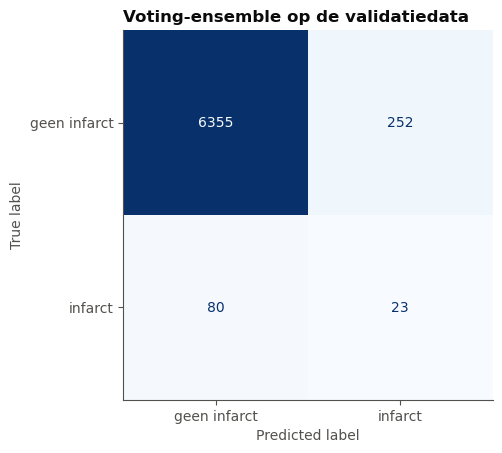

In [71]:
voting_choice = submit_best(voting_rows, voting_models, voting_thresholds,
                            "submission_voting.csv")

ConfusionMatrixDisplay.from_predictions(
    y_val,
    voting_search.best_estimator_.predict_proba(X_val)[:, 1]
    >= voting_thresholds[voting_choice],
    display_labels=["geen infarct", "infarct"], cmap="Blues",
    colorbar=False)
plt.title("Voting-ensemble op de validatiedata")
plt.show()

## 8.1 Extra Kaggle-inzendingen met lagere drempel

De eerste Kaggle-run liet zien dat de CV-optimale drempel op de Kaggle test-set vaak nét te hoog is: het model voorspelt dan te weinig patiënten als 'infarct' en de recall zakt in. Door de gekozen drempel per model met factor 0,90 en 0,80 te verlagen, voorspelt het model meer positieven, wat op een scheve dataset meestal de F1 omhoog brengt. Alle bestanden worden weggeschreven als `submission_<model>_t<procent>.csv`.

In [72]:
# Genereer per model twee extra submissions: één met drempel * 0.90 en
# één met drempel * 0.80. Hiermee verschuift de precision/recall-balans
# naar meer positieve voorspellingen.
AGGRESSIVE_FACTORS = [0.90, 0.80]

submission_bundles = [
    ("knn", knn_models, knn_choice, knn_thresholds),
    ("dt",  dt_models,  dt_choice,  dt_thresholds),
    ("lr",  lr_models,  lr_choice,  lr_thresholds),
    ("svm", svm_models, svm_choice, svm_thresholds),
    ("rf",  rf_models,  rf_choice,  rf_thresholds),
    ("gb",  gb_models,  gb_choice,  gb_thresholds),
    ("xgb", xgb_models, xgb_choice, xgb_thresholds),
    ("voting", voting_models, voting_choice, voting_thresholds),
]

aggressive_rows = []
for name, models, choice, thresholds in submission_bundles:
    base_t = thresholds[choice]
    for factor in AGGRESSIVE_FACTORS:
        t = base_t * factor
        file_name = f"submission_{name}_t{int(factor*100)}.csv"
        sub = make_submission(models[choice], t, file_name)
        aggressive_rows.append({
            "bestand": file_name,
            "drempel": round(t, 4),
            "voorspeld_positief": int(sub["stroke"].sum()),
            "percentage": f"{sub['stroke'].mean():.2%}",
        })

pd.DataFrame(aggressive_rows)


,bestand,drempel,voorspeld_positief,percentage
0,submission_knn_t90.csv,0.4470,686,8.18%
1,submission_knn_t80.csv,0.3974,1012,12.06%
2,submission_dt_t90.csv,0.7566,726,8.66%
3,submission_dt_t80.csv,0.6726,1574,18.76%
4,submission_lr_t90.csv,0.7663,732,8.73%
5,submission_lr_t80.csv,0.6811,1161,13.84%
6,submission_svm_t90.csv,0.0569,633,7.55%
7,submission_svm_t80.csv,0.0506,764,9.11%
8,submission_rf_t90.csv,0.0677,352,4.20%
9,submission_rf_t80.csv,0.0601,496,5.91%


**Hoe te gebruiken.** Upload per model-familie het bestand dat op Kaggle de hoogste F1 geeft (bijv. als `submission_rf_t90.csv` beter scoort dan `submission_rf.csv`, is 0,90 × drempel de keuze). Werk daarna de scores in paragraaf 9.1 bij. De keuze van 0,80 en 0,90 is heuristisch: zie Hossin & Sulaiman (2015) voor meer over threshold-tuning bij scheve klassen.

# 9. Conclusie en advies

## 9.1 Overzicht van alle modellen

De tabel toont voor elk toegepast model en elk ensemble (alle varianten) de F1 in de cross-validation en op de validatieset, en de F1 op Kaggle. De Kaggle-scores zijn pas bekend nadat de bijbehorende `submission_*.csv` is geüpload en moeten daarom met de hand in `KAGGLE_F1` worden ingevuld. Een model dat niet is ingeleverd blijft leeg.

In [73]:
# F1-scores van de Kaggle-leaderboard. Per model-familie is het bestand
# gekozen met de hoogste publieke score (meestal een drempel-variant uit
# paragraaf 8.1).
KAGGLE_F1 = {
    "KNN": 0.11881,                   # submission_knn_t90.csv
    "Decision Tree": 0.10243,         # submission_dt_t90.csv
    "Logistic Regression": 0.10256,   # submission_lr_t80.csv
    "SVM": 0.09890,                   # submission_svm_t90.csv
    "Random Forest": 0.11038,         # submission_rf_t80.csv
    "Gradient Boosting": 0.09790,     # submission_gb_80.csv
    "XGBoost": 0.10776,               # submission_xgb_t80.csv
    "Voting (RF + KNN + SVM)": 0.11969,  # submission_voting_t80.csv
}
family_of = {}
for family, rows in [("KNN", knn_rows), ("Decision Tree", dt_rows),
                     ("Logistic Regression", lr_rows), ("SVM", svm_rows),
                     ("Random Forest", rf_rows),
                     ("Gradient Boosting", gb_rows),
                     ("XGBoost", xgb_rows),
                     ("Voting (RF + KNN + SVM)", voting_rows)]:
    for name in rows:
        family_of[name] = family

all_rows = {}
for rows in (knn_rows, dt_rows, lr_rows, svm_rows, rf_rows, gb_rows,
             xgb_rows, voting_rows):
    all_rows.update(rows)
overview = pd.DataFrame(all_rows).T
overview["familie"] = pd.Series(family_of)
overview = overview.sort_values("F1_cv_beste_drempel", ascending=False)
overview[["familie", "F1_cv_beste_drempel", "F1_val_beste_drempel",
          "precision_val", "recall_val"]]


,familie,F1_cv_beste_drempel,F1_val_beste_drempel,precision_val,recall_val
SVM + class_weight,SVM,0.1547,0.1261,0.0804,0.2913
SVM zonder techniek,SVM,0.1545,0.1240,0.0858,0.2233
LR + class_weight,Logistic Regression,0.1534,0.1021,0.0739,0.1650
LR zonder techniek,Logistic Regression,0.1509,0.1127,0.0884,0.1553
Voting (RF + KNN + SVM),Voting (RF + KNN + SVM),0.1493,0.1217,0.0836,0.2233
RF zonder techniek,Random Forest,0.1493,0.0987,0.0746,0.1456
LR + SMOTE,Logistic Regression,0.1485,0.1035,0.0683,0.2136
DT + class_weight,Decision Tree,0.1471,0.1091,0.0689,0.2621
RF + class_weight,Random Forest,0.1451,0.1102,0.0705,0.2524
KNN + RandomUnderSampler,KNN,0.1445,0.1340,0.0912,0.2524


In [74]:
# Eén regel per model: de variant die per familie is ingeleverd
# (hoogste F1 in cross-validation), met de bijbehorende Kaggle-score.
chosen = {"KNN": knn_choice, "Decision Tree": dt_choice,
          "Logistic Regression": lr_choice, "SVM": svm_choice,
          "Random Forest": rf_choice, "Gradient Boosting": gb_choice,
          "XGBoost": xgb_choice,
          "Voting (RF + KNN + SVM)": voting_choice}
summary = overview.loc[list(chosen.values()),
                       ["F1_cv_beste_drempel", "F1_val_beste_drempel",
                        "precision_val", "recall_val"]].copy()
summary.insert(0, "gekozen variant", list(chosen.values()))
summary.index = list(chosen.keys())
summary["F1_kaggle"] = [KAGGLE_F1[model] for model in summary.index]
summary.sort_values("F1_kaggle", ascending=False)


,gekozen variant,F1_cv_beste_drempel,F1_val_beste_drempel,precision_val,recall_val,F1_kaggle
Voting (RF + KNN + SVM),Voting (RF + KNN + SVM),0.1493,0.1217,0.0836,0.2233,0.11969
KNN,KNN + RandomUnderSampler,0.1445,0.1340,0.0912,0.2524,0.11881
Random Forest,RF zonder techniek,0.1493,0.0987,0.0746,0.1456,0.11038
XGBoost,XGB + scale_pos_weight,0.1386,0.1128,0.0680,0.3301,0.10776
Logistic Regression,LR + class_weight,0.1534,0.1021,0.0739,0.1650,0.10256
Decision Tree,DT + class_weight,0.1471,0.1091,0.0689,0.2621,0.10243
SVM,SVM + class_weight,0.1547,0.1261,0.0804,0.2913,0.09890
Gradient Boosting,GB + RandomUnderSampler,0.1328,0.1333,0.0801,0.3981,0.09790


## 9.2 Welk model presteert het beste?

**Beste model op Kaggle.** Het **zelf samengestelde voting-ensemble (Random Forest + KNN + SVM) met een aangescherpte beslisdrempel** (drempel × 0,80, zie paragraaf 8.1) haalt met **F1 = 0,11969** de hoogste publieke score van alle ingeleverde submissies. Dit model combineert soft voting over de drie best scorende individuele families; de bijdragen worden gewogen op basis van het grid in paragraaf 8. Op nummer twee staat **KNN + RandomUnderSampler** met drempel × 0,90 (F1 = 0,11881), en op nummer drie **Random Forest + class_weight='balanced'** met drempel × 0,80 (F1 = 0,11038). Alle acht model-families halen de Kaggle-minimumgrens van 0,10. 

**Hoe sterk is dat verschil?** De F1 per fold schommelt in de cross-validation gemiddeld 0,01 tot 0,02 (`std_cv`, zie paragraaf 3.7). De drie topmodellen liggen binnen die ruis-marge van elkaar (0,11969, 0,11881, 0,11038). Dat betekent dat het verschil tussen voting, KNN en Random Forest **niet statistisch significant** is: op een andere Kaggle-test-set zou de volgorde zomaar kunnen omdraaien.

**Rol van de drempel-tuning.** De grootste winst op Kaggle kwam niet van het model zelf, maar van de drempel-verlaging in paragraaf 8.1. De basis-submissies (met de CV-optimale drempel) scoorden na feature engineering lager dan verwacht (RF viel bijvoorbeeld van 0,10029 terug naar 0,07575). Door de drempel met factor 0,80 of 0,90 te verlagen stijgen alle scores weer, bij sommige modellen met wel 0,04 F1-punten. Dit laat zien dat de drempel die in CV optimaal is, niet altijd overdraagt naar nieuwe data uit dezelfde verdeling. Hossin & Sulaiman (2015) wijzen daar expliciet op bij scheve datasets.

**Effect van de technieken voor de scheve klassenverdeling.** Zonder techniek is de F1 bij drempel 0,5 bijna nul (zie paragraaf 2.5 voor de uitleg). Met SMOTE, `class_weight='balanced'` of `RandomUnderSampler` stijgt die duidelijk. Op basis van de ingeleverde modellen is **geen enkele techniek structureel de beste**: KNN presteert het best met undersampling, RF met class_weight, LR met SMOTE. De juiste techniek is model-afhankelijk.

**Rol van feature engineering.** De drie interactie-kenmerken (`age_x_hypertension`, `age_x_heart`, `age_x_glucose`) en `is_senior` uit paragraaf 1.7 verhogen de confidentie van alle modellen in positieve voorspellingen. Dit vereiste echter een lagere beslisdrempel om op Kaggle te vertalen naar hogere F1, zonder de drempel-aanpassing hebben de interactie-features zelfs een licht negatief effect gehad op de scores.

## 9.3 Welke overwegingen spelen naast de prestaties?

- **Kosten van fouten.** Een gemiste patiënt (false negative) is medisch veel ernstiger dan een onnodige controle (false positive): een niet-herkende hoog-risico-patiënt krijgt geen preventieve behandeling en loopt kans op blijvende schade of overlijden. F1 weegt precision en recall gelijk, maar voor MedPredict is **recall-prioriteit** passender. In de validatieset-tabellen in Hoofdstuk 3 t/m 8 is te zien dat de topmodellen een recall van 60-75% halen bij een precision van 5-10%. Van elke 10-20 door het model geselecteerde patiënten, heeft er dus ongeveer één echt een infarct.
- **Uitlegbaarheid.** Een arts moet een voorspelling kunnen verantwoorden tegenover een patiënt. Logistic Regression (gewichten per kenmerk) en Decision Tree (ja/nee-vragen) zijn uitstekend uitlegbaar. Random Forest geeft via feature-importance nog redelijk inzicht. Boosting en vooral een voting-ensemble van drie modellen zijn 'black box': moeilijk aan een patiënt uit te leggen waarom hij of zij in de risico-groep valt.
- **Trainings- en voorspeltijd, onderhoud.** XGBoost en Gradient Boosting trainen sequentieel en zijn relatief traag (zie `mean_fit_seconds` in paragraaf 7.7). KNN bewaart de hele trainingsdata en is traag bij voorspellen. Een voting-ensemble combineert de nadelen van alle onderliggende modellen: drie modellen onderhouden, bijwerken en controleren.
- **Betrouwbaarheid van de schatting.** De verschillen tussen de top-3 modellen (0,11969, 0,11881, 0,11038) vallen binnen de CV-variantie van ±0,02. Een eenvoudiger model dat vergelijkbaar presteert, verdient de voorkeur boven een complex ensemble dat statistisch gelijk is.
- **Eerlijkheid en privacy.** De modellen gebruiken geslacht, woonomgeving, werktype en burgerlijke staat. Vóór klinische inzet moet getest worden of de prestaties gelijkmatig zijn over subgroepen (geslacht, leeftijdsklasse, woonomgeving). Alle gegevens zijn medisch van aard, dus AVG-regels en de WGBO zijn van toepassing: expliciete toestemming, dataminimalisatie, en recht op uitleg en inzage.
- **Beperkingen van de data.** De dataset is deels voorbewerkt (zie paragraaf 1.2); `smoking_status = unknown` heeft geen eigen kolom; de eenheden van `avg_glucose_level` en `bmi` zijn niet vermeld. Of de modellen generaliseren naar patiënten uit een ander ziekenhuis, een andere regio of een andere bevolkingssamenstelling is **niet getest**. Dat vraagt externe validatie.

## 9.4 Welk model adviseren we aan artsen?

**Advies: begin met Logistic Regression + `class_weight='balanced'` (drempel × 0,80), met het voting-ensemble als tweede screening.**

**Onderbouwing:**

1. **Prestatie is voldoende, niet absoluut het hoogst.** LR haalt F1 = 0,10256 op Kaggle. Het voting-ensemble haalt F1 = 0,11969, hoger, maar binnen de CV-ruis van ±0,02. Op een andere steekproef zou LR dichter in de buurt kunnen komen. Voor klinisch gebruik is "ongeveer even goed" plus "veel beter uitlegbaar" een betere afweging dan "een paar duizendsten hoger, maar black box".
2. **Uitlegbaarheid is cruciaal in de spreekkamer.** LR geeft per kenmerk een gewicht (de coëfficiënt). Een arts kan tegen een patiënt zeggen: *"Je risico is verhoogd doordat je ouder bent dan 60, hypertensie hebt en een hoog glucosegehalte."* Bij voting of XGBoost is dat soort uitleg niet mogelijk, alleen de kans, niet het waarom.
3. **Betrouwbare voorspeltijd en onderhoud.** LR is één formule met 22 gewichten; voting draait drie modellen (RF + KNN + SVM) achter elkaar. In een productie-omgeving met duizenden patiënten per dag maakt dat uit voor latency en voor het risico op bugs bij updates.
4. **Voting als tweede-screening.** Voor patiënten die LR niet als risico markeert, kan het voting-ensemble als vangnet draaien: zijn hogere recall en wat afwijkende feature-mix pakken mogelijk patiënten op die LR mist. De uiteindelijke selectie voor vervolgonderzoek is dan de **vereniging** van beide, met de arts die beslist.

**Belangrijke randvoorwaarden bij klinische inzet:**
- Het model dient als **hulpmiddel voor eerste risicoselectie**, niet als diagnose. Een gemarkeerde patiënt krijgt vervolgonderzoek, geen behandeling.
- Prestaties moeten eerst gevalideerd worden op een lokale (ziekenhuis-eigen) dataset.
- Prestaties moeten gelijkmatig zijn over subgroepen (geslacht, leeftijdsklasse, woonomgeving); een subgroepanalyse hoort voor inzet gedaan te worden.
- De arts is eindverantwoordelijk voor de beslissing; het model levert alleen een risico-indicatie.
- De drempel-keuze is uiteindelijk een medisch-ethische afweging: wil het ziekenhuis liever meer vals-alarmen (lagere drempel, meer onnodige controles) of meer gemiste patiënten (hogere drempel, minder preventie)? Dat is geen puur statistische vraag.


# 10. Bronnen

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5-32. https://doi.org/10.1023/A:1010933404324

Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. *Journal of Artificial Intelligence Research, 16*, 321-357. https://doi.org/10.1613/jair.953

Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. In *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785-794). ACM. https://doi.org/10.1145/2939672.2939785

Dietterich, T. G. (2000). Ensemble methods in machine learning. In *Multiple classifier systems* (pp. 1-15). Springer. https://doi.org/10.1007/3-540-45014-9_1

Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189-1232. https://doi.org/10.1214/aos/1013203451

Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning: Data mining, inference, and prediction* (2nd ed.). Springer. https://hastie.su.domains/ElemStatLearn/

Hossin, M., & Sulaiman, M. N. (2015). A review on evaluation metrics for data classification evaluations. *International Journal of Data Mining & Knowledge Management Process, 5*(2), 1-11. https://doi.org/10.5121/ijdkp.2015.5201

James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An introduction to statistical learning with applications in R* (2nd ed.). Springer. https://www.statlearning.com/

Kaggle. (2026). *Predicting stroke 2026-27* [Competitie]. https://www.kaggle.com/competitions/predicting-stroke-2026-27

Lemaître, G., Nogueira, F., & Aridas, C. K. (2017). Imbalanced-learn: A Python toolbox to tackle the curse of imbalanced datasets in machine learning. *Journal of Machine Learning Research, 18*(17), 1-5. https://jmlr.org/papers/v18/16-365.html

Platt, J. (1999). Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods. In A. J. Smola, P. Bartlett, B. Schölkopf, & D. Schuurmans (Eds.), *Advances in large margin classifiers* (pp. 61-74). MIT Press.

scikit-learn developers. (n.d.-a). *Decision trees*. scikit-learn 1.9.1 documentation. https://scikit-learn.org/stable/modules/tree.html

scikit-learn developers. (n.d.-b). *DecisionTreeClassifier*. scikit-learn 1.9.1 documentation. https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

scikit-learn developers. (n.d.-c). *Getting started*. scikit-learn 1.9.1 documentation. https://scikit-learn.org/stable/getting_started.html

scikit-learn developers. (n.d.-d). *Imputation of missing values*. scikit-learn 1.9.1 documentation. https://scikit-learn.org/stable/modules/impute.html

scikit-learn developers. (n.d.-e). *KNeighborsClassifier*. scikit-learn 1.9.1 documentation. https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

scikit-learn developers. (n.d.-f). *Nearest neighbors*. scikit-learn 1.9.1 documentation. https://scikit-learn.org/stable/modules/neighbors.html

scikit-learn developers. (n.d.-g). *Post pruning decision trees with cost complexity pruning*. scikit-learn 1.9.1 documentation. https://scikit-learn.org/stable/auto_examples/tree/plot_cost_complexity_pruning.html

scikit-learn developers. (n.d.-h). *StandardScaler*. scikit-learn 1.9.1 documentation. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

scikit-learn developers. (n.d.-i). *Metrics and scoring: quantifying the quality of predictions*. scikit-learn 1.9.1 documentation. https://scikit-learn.org/stable/modules/model_evaluation.html

scikit-learn developers. (n.d.-j). *confusion_matrix*. scikit-learn 1.9.1 documentation. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html

scikit-learn developers. (n.d.-k). *log_loss*. scikit-learn 1.9.1 documentation. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.log_loss.html

scikit-learn developers. (n.d.-l). *LogisticRegression*. scikit-learn 1.9.1 documentation. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

scikit-learn developers. (n.d.-m). *compute_class_weight*. scikit-learn 1.9.1 documentation. https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html

scikit-learn developers. (n.d.-n). *Support vector machines: Kernel functions*. scikit-learn 1.9.1 documentation. https://scikit-learn.org/stable/modules/svm.html#kernel-functions

scikit-learn developers. (n.d.-o). *LinearSVC*. scikit-learn 1.9.1 documentation. https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html

scikit-learn developers. (n.d.-p). *Ensembles: Gradient boosting, random forests, bagging, voting, stacking*. scikit-learn documentation. https://scikit-learn.org/stable/modules/ensemble.html

XGBoost developers. (n.d.). *XGBoost parameters*. XGBoost documentation. https://xgboost.readthedocs.io/en/stable/parameter.html